# Homework 7: Analyzing LFP

This homework will use an EEG dataset from Grenoble, France (https://zenodo.org/records/2358753). In this dataset, subjects were instrumented with 16-channel EEGs and asked to close and then open their eyes. The eyes-closed state is associated with low-frequency alpha oscillations, and in this assignment you will look at those oscillations in different ways.

## How to complete and submit this homework (read this first!)

This works the same in Google Colab, VS Code, or Jupyter.

1. **Put your NetID** in the setup cell below.
2. **Each problem ends with two `ANSWER` cells**: a code cell whose first line is `# ANSWER 1B`, and a text cell that starts with **ANSWER 1B: written answer**. **Everything from the code cell through the written-answer cell is graded together.** Add as many cells as you like between them (more code, more figures, notes). Work anywhere else in the notebook is treated as scratch and isn't graded.
3. **Write your answers in full sentences** in the written-answer cell, and refer to your figures ("the left panel shows..."). Explain your reasoning. Many questions have more than one good approach, and an approach different from ours is fine if you justify it.
4. **Do not delete the `ANSWER` cells or change their first lines.**
5. **If you can't finish a problem, make sure its cells still run without an error** (comment out the broken lines). An error stops "Run All", and every problem after it will then have no output.
6. **Before submitting:** restart and run everything from the top, then check that the last cell in the notebook printed its message.
   - Colab: *Runtime &rarr; Restart session and run all*
   - VS Code / Jupyter: *Restart* the kernel, then *Run All*
7. **Submit the `.ipynb` file to Canvas, not a PDF.** Name it `hw7_<netid>.ipynb`. Your figures are saved inside the file.
   - Colab: *File &rarr; Download &rarr; Download .ipynb*
   - VS Code / Jupyter: save (Ctrl/Cmd-S), then upload the `.ipynb` file from your computer.

In [6]:
NETID = "sj127"   # <-- your Rice NetID, e.g. "abc12"

import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import scipy
import scipy.signal as signal

# Download the data if it isn't next to this notebook (e.g., on Colab)
DATA_URL = 'https://raw.githubusercontent.com/ckemere/elec380/main/HW7/'
for fname in ['subject_06.npz', 'subject_08.npz', 'subject_12.npz']:
    if not os.path.exists(fname):
        print('Downloading', fname)
        urllib.request.urlretrieve(DATA_URL + fname, fname)

print('numpy', np.__version__, '| scipy', scipy.__version__)
assert tuple(int(x) for x in scipy.__version__.split('.')[:2]) >= (1, 12), \
    'This homework needs scipy 1.12 or newer (for ShortTimeFFT). Try: pip install --upgrade scipy'

def load_subject(subject_number):
    # Returns eeg_data (samples x 16 channels), fs, eyes-closed and eyes-opened sample indices, channel labels
    d = np.load('subject_{:02d}.npz'.format(subject_number))
    return (d['eeg_data'], int(d['fs']), d['eyes_closed_indices'].ravel(),
            d['eyes_opened_indices'].ravel(), d['channel_labels'])

numpy 2.4.6 | scipy 1.16.3


To begin with, we'll use data from **Subject 6**. Let's take a look at the data from two channels &mdash; channel 0 and channel 13. Channel 0 is the 'Fp1' channel (pre-frontal, over the left eye). Channel 13 is the 'O1' channel (occipital, on the back left of the skull).

In [7]:
eeg_data, fs, eyes_closed_indices, eyes_opened_indices, channel_labels = load_subject(6)
t_eeg = np.arange(eeg_data.shape[0])/fs   # timestamps based on sampling rate (512 Hz)
t = t_eeg

for ch, lab in enumerate(channel_labels):
    print(ch, lab)

0 Fp1
1 Fp2
2 Fc5
3 Fz
4 Fc6
5 T7
6 Cz
7 T8
8 P7
9 P3
10 Pz
11 P4
12 P8
13 O1
14 Oz
15 O2


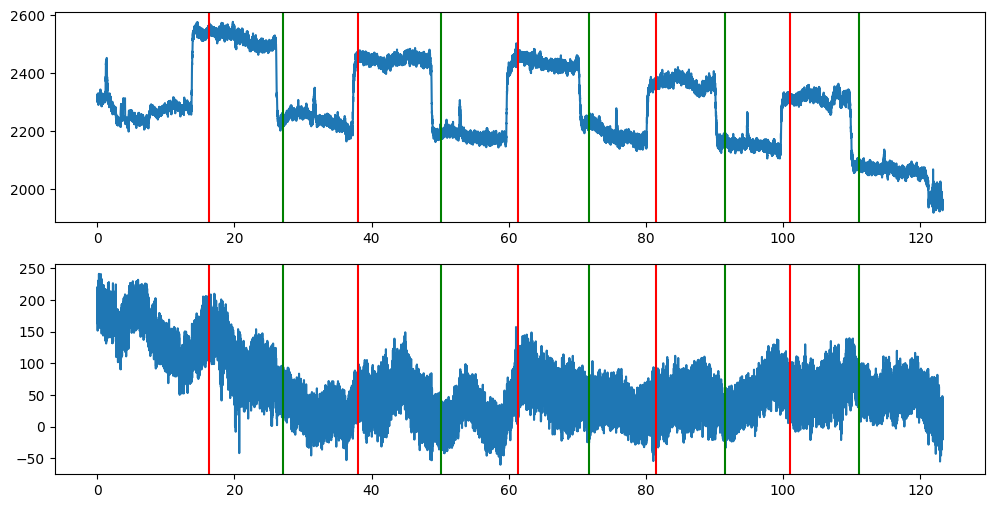

In [8]:
fig, ax = plt.subplots(2,1, figsize=(12,6))

ax[0].plot(t, eeg_data[:,0])  # Plot channel 0 (Fp1)
ax[1].plot(t, eeg_data[:,13]) # Plot channel 13 (O1)

# Plot the moments when the eyes closed and the eyes opened according to the experimenter
for a in ax:
    for closed in eyes_closed_indices:
        a.axvline(t[closed], color='r')
    for opened in eyes_opened_indices:
        a.axvline(t[opened], color='g')

We immediately notice a few things here.

First, there is a large artifact when the eyes are opened and closed. The artifact is larger in the channel near the eyes and smaller in the channel on the back of the head.

Second, the experimenter coding of when the eyes are closed and opened is slightly offset from when it happens in the experiment. We won't worry about this, but Problem 4 below (required for ELEC 587, extra credit for ELEC 380) asks you to correct for it.

What does the data look like if we zoom in around the eye closing period? Looking at the indices, it seems like the timing is better for the second event &mdash; let's use that one to plot.

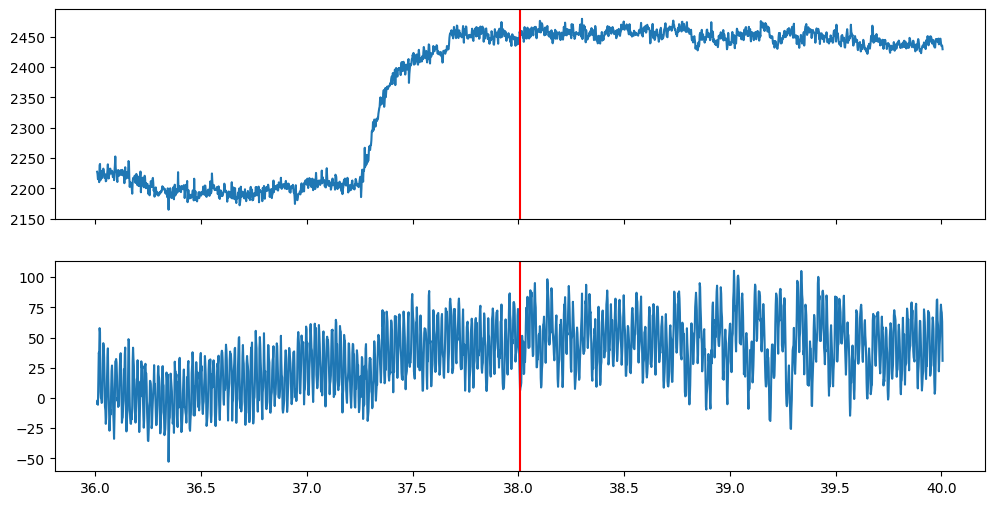

In [9]:
closed_index = eyes_closed_indices[1] # Index of second eyes closing

fig, ax = plt.subplots(2,1, figsize=(12,6), sharex=True)

ax[0].plot(t[closed_index - 1024: closed_index + 1024], eeg_data[closed_index - 1024: closed_index + 1024, 0])
ax[1].plot(t[closed_index - 1024: closed_index + 1024], eeg_data[closed_index - 1024: closed_index + 1024, 13])
ax[0].axvline(t[closed_index], color='r')
ax[1].axvline(t[closed_index], color='r')

# Problem 1: Looking at data in the frequency domain

Let's begin by asking a question. What channel has the highest change in power in the alpha band during the eyes-closed state? To answer this question, we will extract the signal during the eyes-closed and eyes-open periods. The experimenters specify that these periods last 10 s, but we've already seen that the onsets/offsets are pretty noisy (maybe 1&ndash;4 seconds after the actual event). So let's extract 4-second windows of signal starting 4 seconds after each cue.

In [10]:
eyes_closed_signals = []
eyes_opened_signals = []
window_indices = np.arange(4*fs) + 4*fs # 4 s of samples starting 4 s after the cue

for closed in eyes_closed_indices:
    eyes_closed_signals.append(eeg_data[closed + window_indices,:])

for opened in eyes_opened_indices:
    eyes_opened_signals.append(eeg_data[opened + window_indices,:])

Now, let's calculate the "Power Spectral Density" for each of these little windows for channel 0 and channel 13 (eyes closed in red, eyes open in green).

Text(0.5, 0, 'Frequency (Hz)')

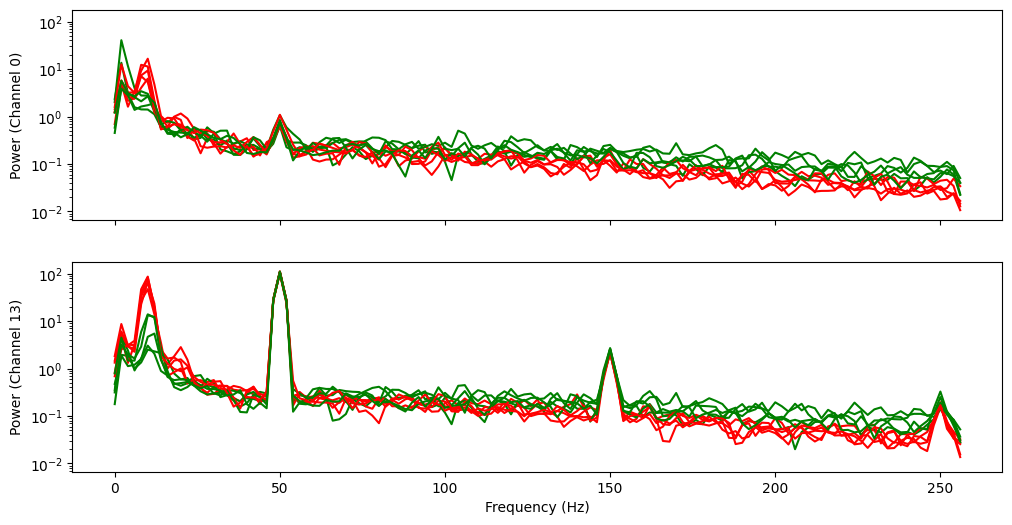

In [11]:
fig, ax = plt.subplots(2,1, figsize=(12,6), sharex=True, sharey=True)

for i in range(5):
    # Calculate and plot the PSDs for channel 0
    f, Pxx = signal.welch(eyes_closed_signals[i][:,0], fs, nperseg=256)
    ax[0].semilogy(f,Pxx, 'r')
    f, Pxx = signal.welch(eyes_opened_signals[i][:,0], fs, nperseg=256)
    ax[0].semilogy(f,Pxx, 'g')

    # Calculate and plot the PSDs for channel 13
    f, Pxx = signal.welch(eyes_closed_signals[i][:,13], fs, nperseg=256)
    ax[1].semilogy(f,Pxx, 'r')
    f, Pxx = signal.welch(eyes_opened_signals[i][:,13], fs, nperseg=256)
    ax[1].semilogy(f,Pxx, 'g')
ax[0].set_ylabel('Power (Channel 0)')
ax[1].set_ylabel('Power (Channel 13)')
ax[1].set_xlabel('Frequency (Hz)')

To answer our question, we have to decide what frequency band alpha should be. Let's zoom in on our spectra in the relevant range.

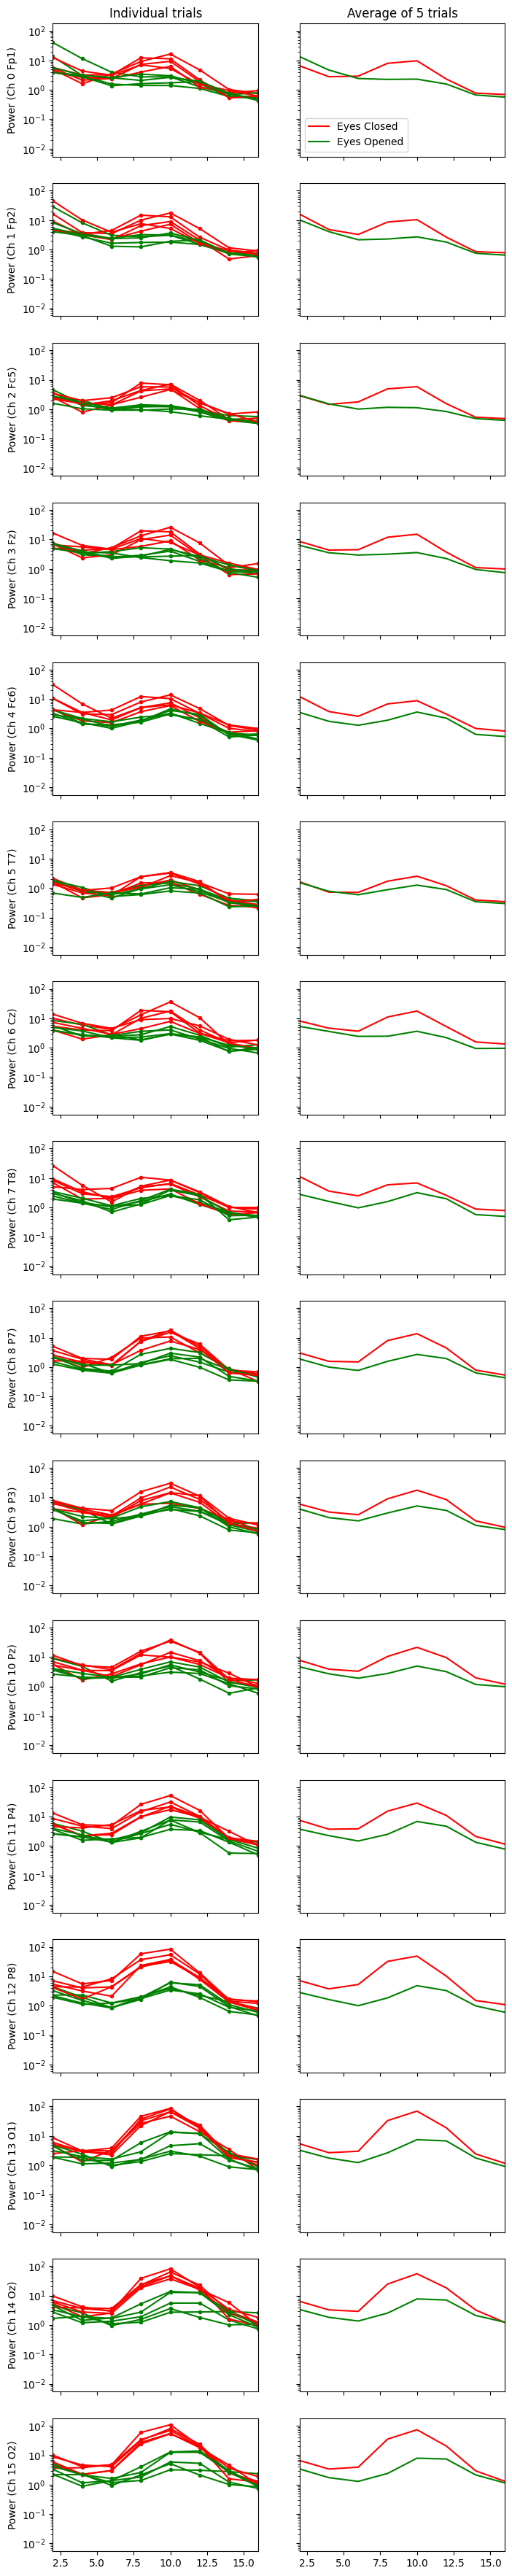

In [12]:
fig, ax = plt.subplots(16,2, figsize=(8,45), sharex=True, sharey=True)

nperseg = 256

for ch in range(16):
    eyes_closed_Pxx = []
    eyes_opened_Pxx = []
    for i in range(5):
        f, Pxx = signal.welch(eyes_closed_signals[i][:,ch], fs, nperseg=nperseg)
        ax[ch,0].plot(f,Pxx, 'r.-')
        eyes_closed_Pxx.append(Pxx)
        f, Pxx = signal.welch(eyes_opened_signals[i][:,ch], fs, nperseg=nperseg)
        ax[ch,0].plot(f,Pxx, 'g.-')
        eyes_opened_Pxx.append(Pxx)

    ax[ch,1].semilogy(f, np.mean(eyes_closed_Pxx, axis=0), 'r', label='Eyes Closed')
    ax[ch,1].semilogy(f, np.mean(eyes_opened_Pxx, axis=0), 'g', label='Eyes Opened')
    ax[ch,0].set_ylabel('Power (Ch {} {})'.format(ch, channel_labels[ch]))

ax[0,0].set_title('Individual trials')
ax[0,1].set_title('Average of 5 trials')
ax[0,0].set_xlim(2,16)
ax[0,1].legend()

## Problem 1A (10 pts): What frequency is the alpha rhythm for this subject?

Recall that naively using the Fourier transform on the data will result in frequency estimates that may be noisy. The Welch PSD method averages the results of smaller, overlapping windows (with size set by the `nperseg` parameter). This results in less noisy estimates, but lower frequency resolution (shorter window &harr; lower frequency resolution). Try several values of `nperseg` and see whether that changes your answer.

Make at least one figure that shows the evidence for your answer.

Alpha peak frequency (Hz), eyes closed:
   nperseg        O1        Oz        O2
       256     10.00     10.00     10.00
       512     10.00     10.00     10.00
      1024      9.50      9.50      9.50
      2048      9.75      9.75      9.75


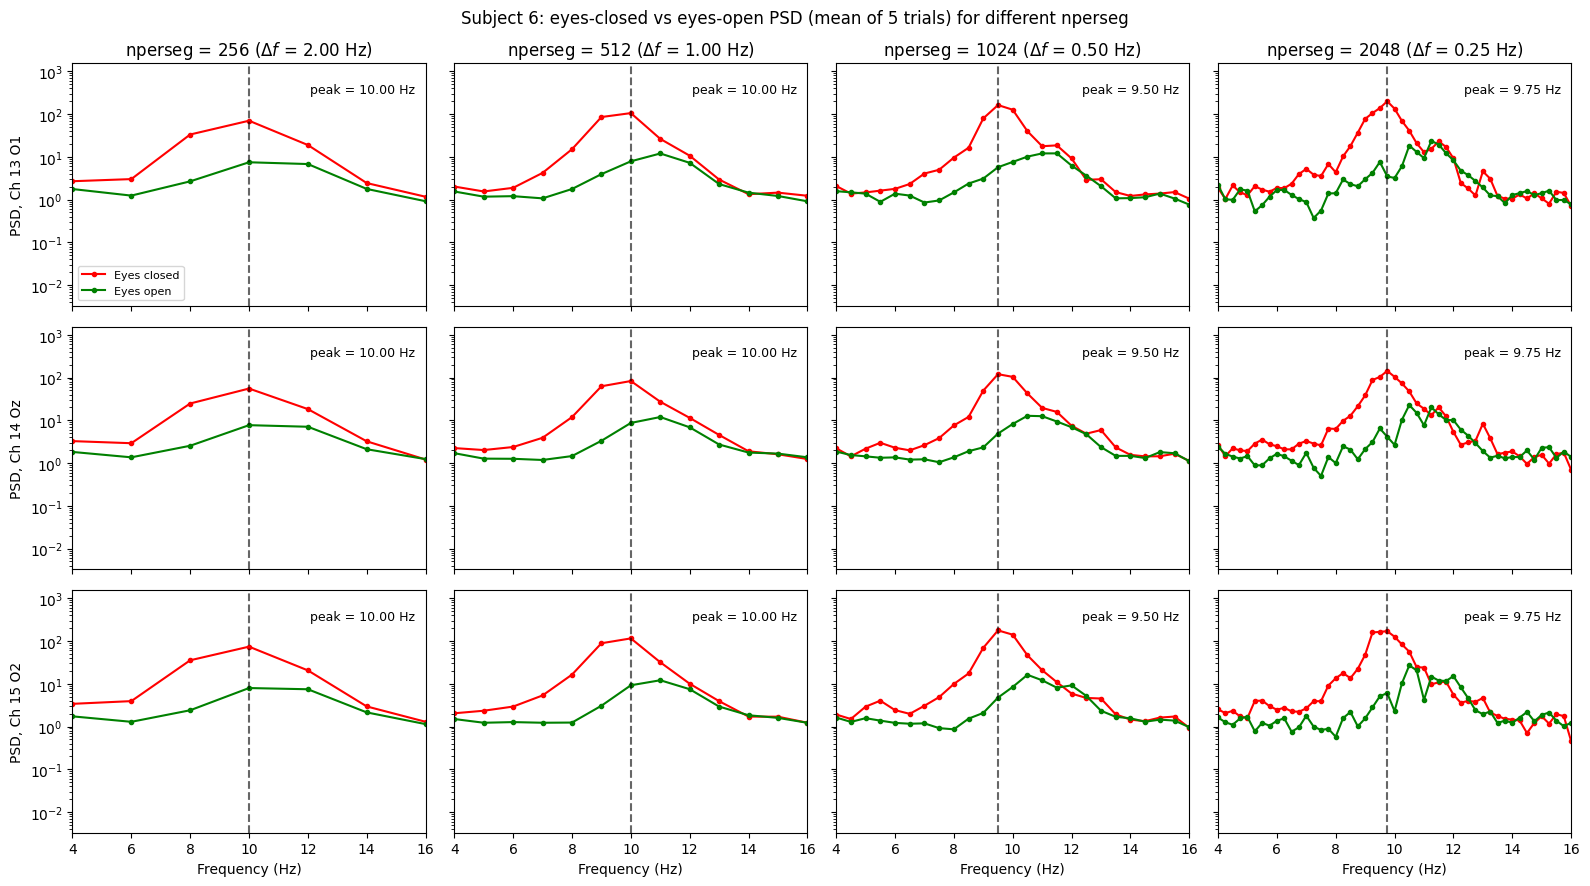

In [13]:
# ANSWER 1A
# your code here
occipital_chs = [13, 14, 15]           # O1, Oz, O2: the clearest alpha in the 16-channel grid above
nperseg_list = [256, 512, 1024, 2048]  # frequency resolution: 2, 1, 0.5, 0.25 Hz

closed_arr = np.array(eyes_closed_signals)   # shape: (5 trials, 2048 samples, 16 channels)
opened_arr = np.array(eyes_opened_signals)

fig, ax = plt.subplots(len(occipital_chs), len(nperseg_list), figsize=(16, 9),
                       sharex=True, sharey=True)
peak_table = {}

for col, nps in enumerate(nperseg_list):
    f, Pc = signal.welch(closed_arr, fs, axis=1, nperseg=nps)
    f, Po = signal.welch(opened_arr, fs, axis=1, nperseg=nps)
    Pc_mean = Pc.mean(axis=0)   # average over the 5 trials -> (freqs, channels)
    Po_mean = Po.mean(axis=0)
    band = (f >= 6) & (f <= 14)  # only look for the peak inside 6-14 Hz

    for row, ch in enumerate(occipital_chs):
        a = ax[row, col]
        a.semilogy(f, Pc_mean[:, ch], 'r.-', label='Eyes closed')
        a.semilogy(f, Po_mean[:, ch], 'g.-', label='Eyes open')

        peak_f = f[band][Pc_mean[band, ch].argmax()]
        peak_table[(ch, nps)] = peak_f
        a.axvline(peak_f, color='k', linestyle='--', alpha=0.6)
        a.text(0.97, 0.92, 'peak = {:.2f} Hz'.format(peak_f), transform=a.transAxes,
               ha='right', va='top', fontsize=9)

        if row == 0:
            a.set_title('nperseg = {} ($\\Delta f$ = {:.2f} Hz)'.format(nps, fs/nps))
        if col == 0:
            a.set_ylabel('PSD, Ch {} {}'.format(ch, channel_labels[ch]))
        if row == len(occipital_chs) - 1:
            a.set_xlabel('Frequency (Hz)')

ax[0, 0].set_xlim(4, 16)
ax[0, 0].legend(loc='lower left', fontsize=8)
fig.suptitle('Subject 6: eyes-closed vs eyes-open PSD (mean of 5 trials) for different nperseg')
fig.tight_layout()

# Summary table of the eyes-closed alpha peak
print('Alpha peak frequency (Hz), eyes closed:')
print('{:>10}'.format('nperseg') + ''.join('{:>10}'.format(str(channel_labels[ch])) for ch in occipital_chs))
for nps in nperseg_list:
    print('{:>10}'.format(nps) + ''.join('{:>10.2f}'.format(peak_table[(ch, nps)]) for ch in occipital_chs))

**ANSWER 1A: written answer**

- What is the alpha frequency for Subject 6? Which channel(s) did you base this on?
- What values of `nperseg` did you try, and did they change your estimate? Why or why not?

_Your answer:_

The alpha rhythm for Subject 6 is at approximately 10 Hz. I based this on the three occipital channels, O1 (13), Oz (14), and O2 (15), because the 16-channel grid above shows that these channels have the largest eyes-closed alpha peak and the biggest separation between the eyes-closed and eyes-open spectra.

I tried nperseg = 256, 512, 1024, and 2048, which correspond to frequency resolutions of 2, 1, 0.5, and 0.25 Hz (fs / nperseg). With 256 and 512 samples, the peak lands on 10 Hz. In the 512 column, the 9 Hz point is almost as high as the 10 Hz point, suggesting that the true peak lies between them. With 1024 and 2048 samples, the peak shifts down slightly to 9.5 and 9.75 Hz. These two values differ by only one or two frequency bins, so I treat them as the same estimate. With nperseg = 2048, each 4-second window contains only one segment, so Welch’s method has nothing to average and the spectrum becomes very noisy (based on rightmost column). nperseg = 1024 gives a good balance between resolution and smoothness. So changing nperseg refined the estimate from about 10 Hz to about 9.5–10 Hz, but the overall conclusion doesn't change.


## Problem 1B (20 pts): Which channel shows the largest alpha signal when the eyes are closed? Which shows the largest difference between eyes open and eyes closed?

Below is a function that combines the cells above to calculate the average alpha power for a given `frequency` (the alpha frequency you decided on) and `eeg_channel`. Use it (or modify it) to compute, for every channel, the eyes-closed alpha power and the ratio of eyes-closed to eyes-open alpha power. The answer cell has a loop to fill in and an example of how to plot the result.

In [14]:
def extract_alpha_power(eeg_channel=0, frequency=10, nperseg=256, window_size=4.0, window_offset=4.0):
    eyes_closed_signals = []
    eyes_opened_signals = []
    window_indices = np.arange(int(window_size*fs)) + int(window_offset*fs) # index into the data for the time windows

    for closed in eyes_closed_indices:
        eyes_closed_signals.append(eeg_data[closed + window_indices,:])

    for opened in eyes_opened_indices:
        eyes_opened_signals.append(eeg_data[opened + window_indices,:])

    # axis 0 is trials, axis 1 is time, axis 2 is channel
    f, eyes_closed_Pxx = signal.welch(np.array(eyes_closed_signals), fs, axis=1, nperseg=nperseg)
    f, eyes_opened_Pxx = signal.welch(np.array(eyes_opened_signals), fs, axis=1, nperseg=nperseg)

    fidx = np.abs(f - frequency).argmin()
    print('Channel {}: using frequency {} ({} specified).'.format(eeg_channel, f[fidx], frequency))

    return np.mean(eyes_closed_Pxx[:,fidx,eeg_channel], axis=0), np.mean(eyes_opened_Pxx[:,fidx,eeg_channel], axis=0)


# Example data point
eyes_closed_power, eyes_opened_power = extract_alpha_power(eeg_channel=13, frequency=6.9)
print(eyes_closed_power)

Channel 13: using frequency 6.0 (6.9 specified).
3.014758924974393


Channel 0: using frequency 10.0 (10 specified).
Channel 1: using frequency 10.0 (10 specified).
Channel 2: using frequency 10.0 (10 specified).
Channel 3: using frequency 10.0 (10 specified).
Channel 4: using frequency 10.0 (10 specified).
Channel 5: using frequency 10.0 (10 specified).
Channel 6: using frequency 10.0 (10 specified).
Channel 7: using frequency 10.0 (10 specified).
Channel 8: using frequency 10.0 (10 specified).
Channel 9: using frequency 10.0 (10 specified).
Channel 10: using frequency 10.0 (10 specified).
Channel 11: using frequency 10.0 (10 specified).
Channel 12: using frequency 10.0 (10 specified).
Channel 13: using frequency 10.0 (10 specified).
Channel 14: using frequency 10.0 (10 specified).
Channel 15: using frequency 10.0 (10 specified).

Top 4 channels by eyes-closed alpha power:
    O2 (ch 15):   73.61
    O1 (ch 13):   69.78
    Oz (ch 14):   55.18
    P8 (ch 12):   48.61
Top 4 channels by closed/open ratio:
    P8 (ch 12):   10.15
    O1 (ch 13):    9.36
 

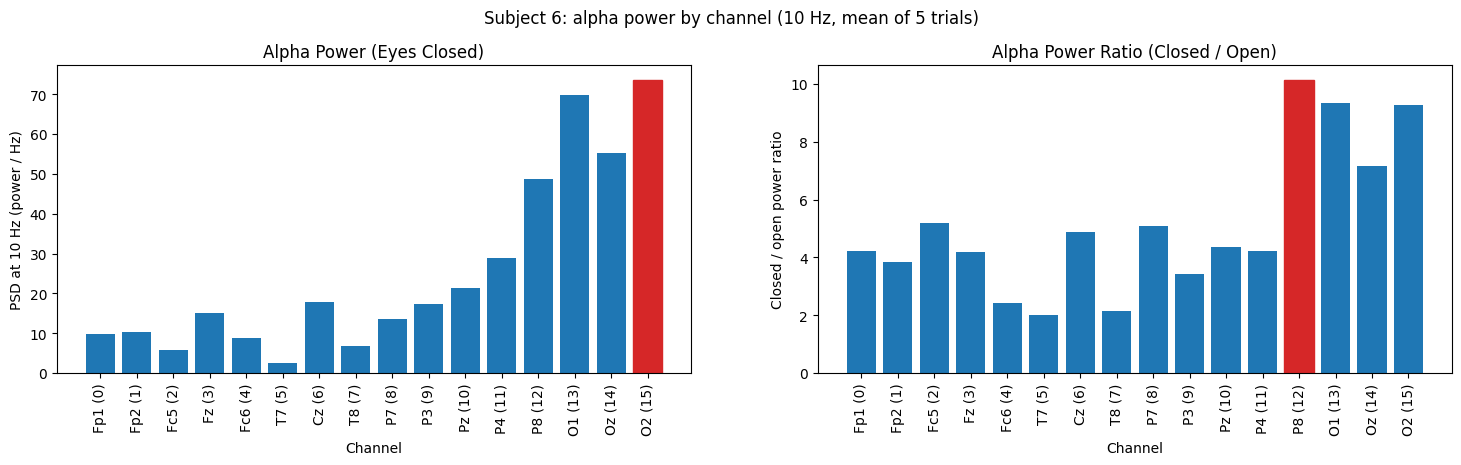

In [15]:
# ANSWER 1B
alpha_freq = 10   # alpha frequency chosen in Problem 1A

alpha_power = []
alpha_power_ratio = []
for ch in range(16):
    closed_p, opened_p = extract_alpha_power(eeg_channel=ch, frequency=alpha_freq)
    alpha_power.append(closed_p)
    alpha_power_ratio.append(closed_p / opened_p)

# Plotting code
if len(alpha_power) == 16 and len(alpha_power_ratio) == 16:
    fig, ax = plt.subplots(1,2, figsize=(18,4))
    plot_labels = ['{} ({})'.format(lab, ch) for ch, lab in enumerate(channel_labels)]
    ax[0].bar(plot_labels, alpha_power)
    ax[0].tick_params(axis='x', labelrotation=90)
    ax[0].set_title('Alpha Power (Eyes Closed)')
    ax[1].bar(plot_labels, alpha_power_ratio)
    ax[1].tick_params(axis='x', labelrotation=90)
    ax[1].set_title('Alpha Power Ratio (Closed / Open)')

    # Added: axis labels, and highlight the largest bar in each panel in red
    ax[0].set_ylabel('PSD at {} Hz (power / Hz)'.format(alpha_freq))
    ax[1].set_ylabel('Closed / open power ratio')
    for a in ax:
        a.set_xlabel('Channel')
    ax[0].patches[int(np.argmax(alpha_power))].set_color('tab:red')
    ax[1].patches[int(np.argmax(alpha_power_ratio))].set_color('tab:red')
    fig.suptitle('Subject 6: alpha power by channel ({} Hz, mean of 5 trials)'.format(alpha_freq), y=1.02)

# Ranked summary
order_p = np.argsort(alpha_power)[::-1]
order_r = np.argsort(alpha_power_ratio)[::-1]
print('\nTop 4 channels by eyes-closed alpha power:')
for ch in order_p[:4]:
    print('  {:>4} (ch {:2d}): {:7.2f}'.format(channel_labels[ch], ch, alpha_power[ch]))
print('Top 4 channels by closed/open ratio:')
for ch in order_r[:4]:
    print('  {:>4} (ch {:2d}): {:7.2f}'.format(channel_labels[ch], ch, alpha_power_ratio[ch]))

**ANSWER 1B: written answer**

- Which channel has the largest eyes-closed alpha power? Which has the largest eyes-closed / eyes-open ratio?
- Where on the head are they? Does it make sense that these locations show the strongest alpha?

_Your answer:_

The channel with the largest eyes-closed alpha power is O2 (channel 15), at about 73.6. The channel with the largest eyes-closed / eyes-open ratio is P8 (channel 12), at about 10.2.

All of these channels sit over the back of the head: O1, Oz, and O2 are over the occipital lobe, and P8 is at the right parietal-occipital junction. The left panel shows a clear front-to-back gradient, with the frontal (Fp1, Fp2) and temporal (T7, T8) channels showing the weakest alpha. This makes sense because the occipital lobe contains the visual cortex. When the eyes close, visual input disappears and large populations of visual-cortex neurons fall into a synchronized idling rhythm, which is the classic posterior alpha. When the eyes open, incoming visual information desynchronizes this activity, so the alpha power drops sharply.

## Problem 1C (10 pts): Which channel has the most noise?

Which channel has the most line noise (which is at 50 Hz in France!)? You can use windows like the ones above, though line noise shouldn't be different with eyes open and eyes closed. Alternatively, look at the whole session. Choose an approach and make a figure that supports your answer.

Channels ranked by 50 Hz power:
    O1 (ch 13): power =    845.2, peak above background =  35.1 dB
    Pz (ch 10): power =    545.6, peak above background =  33.1 dB
    O2 (ch 15): power =    400.3, peak above background =  31.9 dB
    Oz (ch 14): power =    264.3, peak above background =  30.1 dB
    T8 (ch  7): power =     76.7, peak above background =  25.3 dB
Channel with the least 50 Hz power: Fp1 (ch 0), 4.4


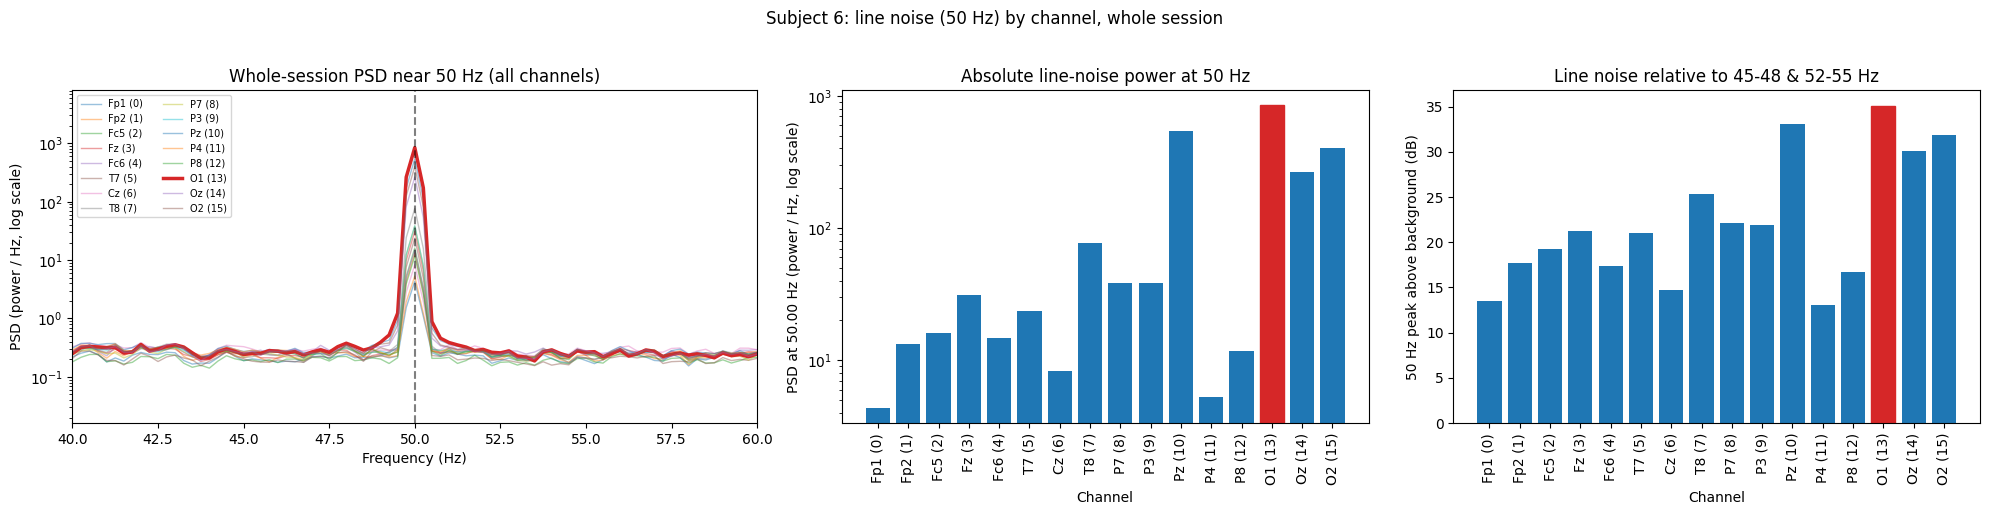

In [16]:
# ANSWER 1C
# your code here
# Line noise does not depend on eye state, so use the whole session for the most stable estimate.
nperseg_ln = 2048                      # 0.25 Hz resolution, and still hundreds of segments to average
f_ln, P_ln = signal.welch(eeg_data, fs, axis=0, nperseg=nperseg_ln)   # P_ln: (freqs, 16 channels)

line_idx = np.abs(f_ln - 50).argmin()                                       # bin closest to 50 Hz
neighbor = ((f_ln >= 45) & (f_ln <= 48)) | ((f_ln >= 52) & (f_ln <= 55))    # nearby "background" bins

line_power = P_ln[line_idx, :]                          # absolute power at 50 Hz
background = np.median(P_ln[neighbor, :], axis=0)       # typical EEG power just around 50 Hz
line_snr_db = 10*np.log10(line_power / background)      # how far the 50 Hz peak sticks out (dB)

worst_abs = int(np.argmax(line_power))
worst_snr = int(np.argmax(line_snr_db))

fig, ax = plt.subplots(1, 3, figsize=(20, 5), gridspec_kw={'width_ratios': [1.3, 1, 1]})

# Left: PSD around 50 Hz for every channel, worst channel drawn thick
for ch in range(16):
    lw, alpha = (2.5, 1.0) if ch == worst_abs else (1.0, 0.45)
    ax[0].semilogy(f_ln, P_ln[:, ch], lw=lw, alpha=alpha,
                   label='{} ({})'.format(channel_labels[ch], ch))
ax[0].axvline(50, color='k', linestyle='--', alpha=0.5)
ax[0].set_xlim(40, 60)
ax[0].set_xlabel('Frequency (Hz)')
ax[0].set_ylabel('PSD (power / Hz, log scale)')
ax[0].set_title('Whole-session PSD near 50 Hz (all channels)')
ax[0].legend(fontsize=7, ncol=2, loc='upper left')

plot_labels = ['{} ({})'.format(lab, ch) for ch, lab in enumerate(channel_labels)]

# Middle: absolute 50 Hz power
bars = ax[1].bar(plot_labels, line_power)
bars[worst_abs].set_color('tab:red')
ax[1].set_yscale('log')
ax[1].tick_params(axis='x', labelrotation=90)
ax[1].set_xlabel('Channel')
ax[1].set_ylabel('PSD at {:.2f} Hz (power / Hz, log scale)'.format(f_ln[line_idx]))
ax[1].set_title('Absolute line-noise power at 50 Hz')

# Right: 50 Hz peak relative to the neighboring frequencies
bars = ax[2].bar(plot_labels, line_snr_db)
bars[worst_snr].set_color('tab:red')
ax[2].tick_params(axis='x', labelrotation=90)
ax[2].set_xlabel('Channel')
ax[2].set_ylabel('50 Hz peak above background (dB)')
ax[2].set_title('Line noise relative to 45-48 & 52-55 Hz')

fig.suptitle('Subject 6: line noise (50 Hz) by channel, whole session', y=1.02)
fig.tight_layout()

order = np.argsort(line_power)[::-1]
print('Channels ranked by 50 Hz power:')
for ch in order[:5]:
    print('  {:>4} (ch {:2d}): power = {:8.1f}, peak above background = {:5.1f} dB'.format(
        channel_labels[ch], ch, line_power[ch], line_snr_db[ch]))
print('Channel with the least 50 Hz power: {} (ch {}), {:.1f}'.format(
    channel_labels[order[-1]], order[-1], line_power[order[-1]]))

**ANSWER 1C: written answer**

- Which channel has the most line noise, and how did you measure it?

_Your answer:_

O1 (channel 13) has the most line noise.

Because line noise comes from the power mains and does not depend on whether the eyes are open or closed, I used the whole session, which gives a much more stable estimate. I computed the Welch PSD of each channel with nperseg = 2048 (0.25 Hz resolution, with hundreds of segments to average) and measured line noise in two ways: (1) the absolute PSD at 50 Hz, and (2) how far the 50 Hz peak rises above the median PSD in the neighboring 45–48 Hz and 52–55 Hz bands, in dB. The second measure checks that a channel is not ranked highly just because its overall signal is larger.

# Problem 2: Calculating a Fourier-based spectrogram

The "Short Time Fourier Transform" (STFT) is the technical term for the standard Fourier-transform-based spectrogram. To avoid the issues that come from sharp window boundaries, the STFT uses windows with rounded edges. In the example code below, we use one of the standard windows, the "Hamming window". Other common choices include Gaussian, triangular, and Hann windows. As we discussed in class, the choice of the window length (`Nx` in the `get_window()` call below) directly affects time/frequency resolution &mdash; longer windows have better resolution in frequency and worse resolution in time. The `hop` parameter specifies how far the window slides each step. Making `hop` smaller costs more computation but can give better temporal resolution (keeping in mind that the window size also affects that!).

The code below calculates and plots the spectrogram for channel 0. The choice `Nx=2048` gives high resolution in frequency.

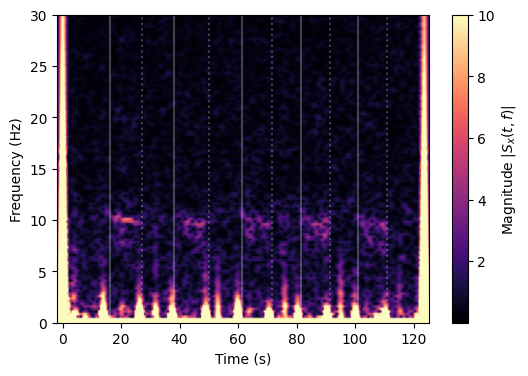

In [17]:
hamm_win = signal.get_window('hamming', Nx=2048)
SFT = signal.ShortTimeFFT(hamm_win, hop=32, fs=fs, scale_to='psd') # 'psd' scaling affects how the signal is normalized across frequency
stft = SFT.stft(eeg_data, axis=0)

fig, ax = plt.subplots(1,1,figsize=(6,4))
im = ax.imshow((abs(stft[:,0,:])), origin='lower', aspect='auto',
                 extent=SFT.extent(eeg_data.shape[0]), cmap='magma', vmax=10)
fig.colorbar(im, label="Magnitude $|S_x(t, f)|$")
ax.set_ylabel('Frequency (Hz)')
ax.set_xlabel('Time (s)')
ax.set_ylim(0, 30)
[ax.axvline(t_eeg[idx], color='white', alpha=0.25) for idx in eyes_closed_indices]
[ax.axvline(t_eeg[idx], linestyle=':', color='white', alpha=0.25) for idx in eyes_opened_indices];

Different subjects (and channels) have very different signal amplitudes, so a fixed `vmax=10` doesn't work for everyone. The function below plots a spectrogram of one channel in a standard way: it removes the channel's mean (which otherwise creates large artifacts at the start and end), and sets the color scale from the 99th percentile of the 2&ndash;30 Hz power. You are welcome to use it in Problems 2A and 2B.

In [18]:
def plot_spectrogram(ax, x, fs, closed_indices, opened_indices, title, Nx=2048, hop=32):
    # x is a single channel (1-D array). Returns the image so you can add a colorbar.
    x = x - np.mean(x)
    SFT = signal.ShortTimeFFT(signal.get_window('hamming', Nx=Nx), hop=hop, fs=fs, scale_to='psd')
    S = np.abs(SFT.stft(x))
    vmax = np.percentile(S[(SFT.f > 2) & (SFT.f < 30)], 99)
    im = ax.imshow(S, origin='lower', aspect='auto', extent=SFT.extent(len(x)), cmap='magma', vmax=vmax)
    ax.set_ylim(0, 30)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Frequency (Hz)')
    ax.set_title(title)
    for idx in closed_indices:
        ax.axvline(idx/fs, color='white', alpha=0.4)
    for idx in opened_indices:
        ax.axvline(idx/fs, color='white', linestyle=':', alpha=0.4)
    return im

## Problem 2A (10 pts): Spectrogram of alpha

Using the channel you settled on as "best" in Problem 1, plot the spectrogram of Subject 6 through the eye closings and openings. Try other values of `Nx` to see how they change the spectrogram. Show whichever version(s) you think best support your answer.

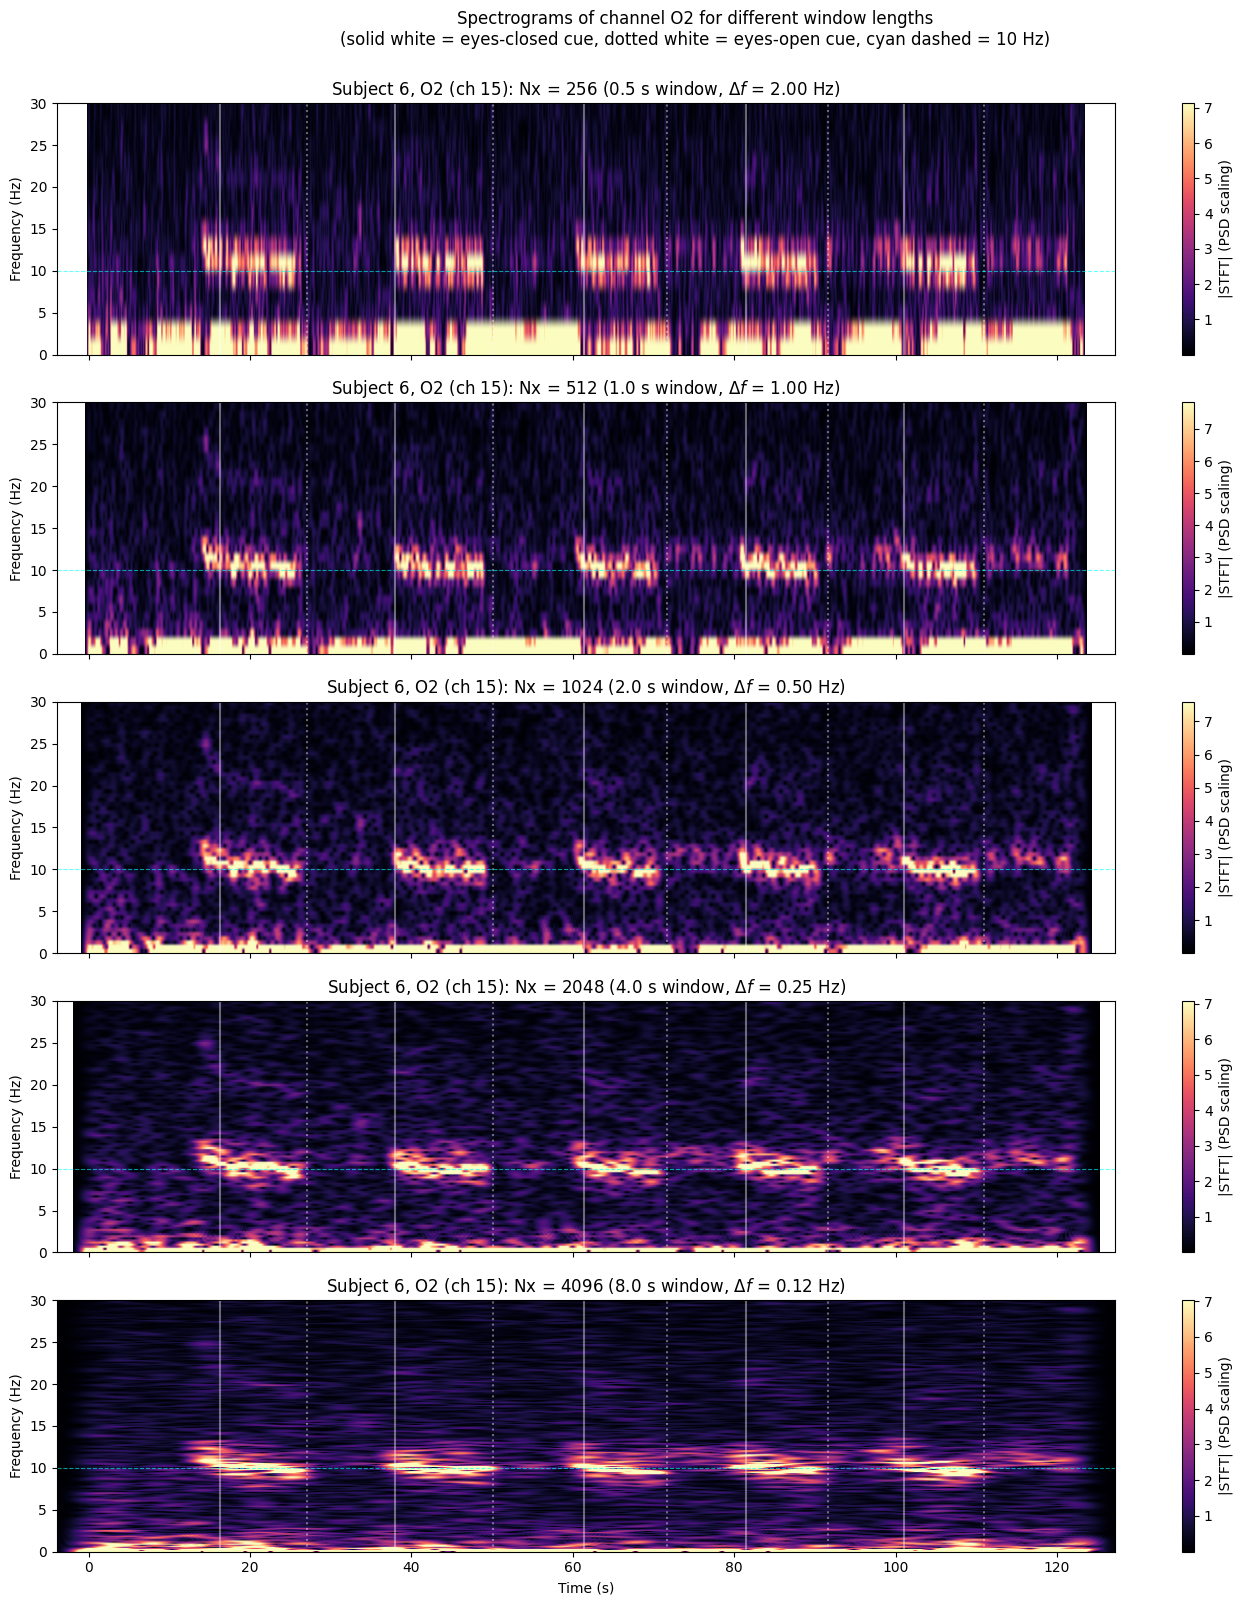

In [19]:
# ANSWER 2A
# your code here
best_ch = 15   # O2: largest eyes-closed alpha power in Problem 1B
Nx_list = [256, 512, 1024, 2048, 4096]   # window length: 0.5 s, 1 s, 2 s, 4 s, 8 s

fig, ax = plt.subplots(len(Nx_list), 1, figsize=(14, 3.2*len(Nx_list)), sharex=True)
for a, Nx in zip(ax, Nx_list):
    title = 'Subject 6, {} (ch {}): Nx = {} ({:.1f} s window, $\\Delta f$ = {:.2f} Hz)'.format(
        channel_labels[best_ch], best_ch, Nx, Nx/fs, fs/Nx)
    im = plot_spectrogram(a, eeg_data[:, best_ch], fs, eyes_closed_indices, eyes_opened_indices,
                          title, Nx=Nx)
    a.axhline(10, color='cyan', linestyle='--', lw=0.8, alpha=0.6)   # alpha frequency from 1A
    fig.colorbar(im, ax=a, label='|STFT| (PSD scaling)')
    if a is not ax[-1]:
        a.set_xlabel('')   # only label the time axis on the bottom panel

fig.suptitle('Spectrograms of channel O2 for different window lengths\n'
             '(solid white = eyes-closed cue, dotted white = eyes-open cue, cyan dashed = 10 Hz)', y=1.0)
fig.tight_layout()

**ANSWER 2A: written answer**

- What happens in the alpha band when the eyes close, and when they open?
- How did changing `Nx` affect what you could see?

_Your answer:_

In every panel, a bright band appears near 10 Hz shortly after each eyes-closed cue, stays on while the eyes are closed, and disappears when the eyes open. The band usually starts at or slightly before the solid line and ends a second or two before the dotted line. During the eyes-open periods, the alpha band is mostly gone, although faint patches around 11–12 Hz remain in some of the later open periods (visible in the Nx = 1024 and 2048 panels).

Changing Nx shows the time–frequency tradeoff clearly. With Nx = 256 (top panel), the start and end of each alpha period are sharp in time, but the frequency resolution is only 2 Hz, so the alpha band is smeared over roughly 8–14 Hz and its exact frequency cannot be read off. The lowest frequencies (0–4 Hz) are also smeared into a wide bright band. As Nx increases to 1024 and 2048, the alpha band becomes a thin line, and a new detail appears: at the start of each eyes-closed period, the alpha frequency is around 12–13 Hz and then drifts down to about 10 Hz over a few seconds. With Nx = 4096 (bottom panel), the frequency resolution is the finest (0.125 Hz), but each time point now mixes in 8 seconds of signal, so the alpha bands are visibly stretched in time and spill past the eye-opening cues.

## Problem 2B (15 pts): Does the frequency of alpha sweep?

In Subject 6, it seems like the frequency of the alpha rhythm sweeps downward slightly following eye closing. Load and plot spectrograms from Subjects 8 and 12. Do you see the same phenomenon in these subjects?

Use `load_subject(8)` and `load_subject(12)`, and **load them into new variable names** (e.g., `eeg_8, fs_8, closed_8, opened_8, labels_8 = load_subject(8)`) so that `eeg_data` still holds Subject 6 for Problem 3. Alpha is weaker in these subjects and the best channel may be different.

Subject 8: top channels by ratio: P4 (ch 11) = 1.91, P3 (ch 9) = 1.74, P7 (ch 8) = 1.69 | eyes-closed peak on best channel: 9.5 Hz
Subject 12: top channels by ratio: P4 (ch 11) = 2.96, Cz (ch 6) = 2.60, P8 (ch 12) = 2.59 | eyes-closed peak on best channel: 10.0 Hz


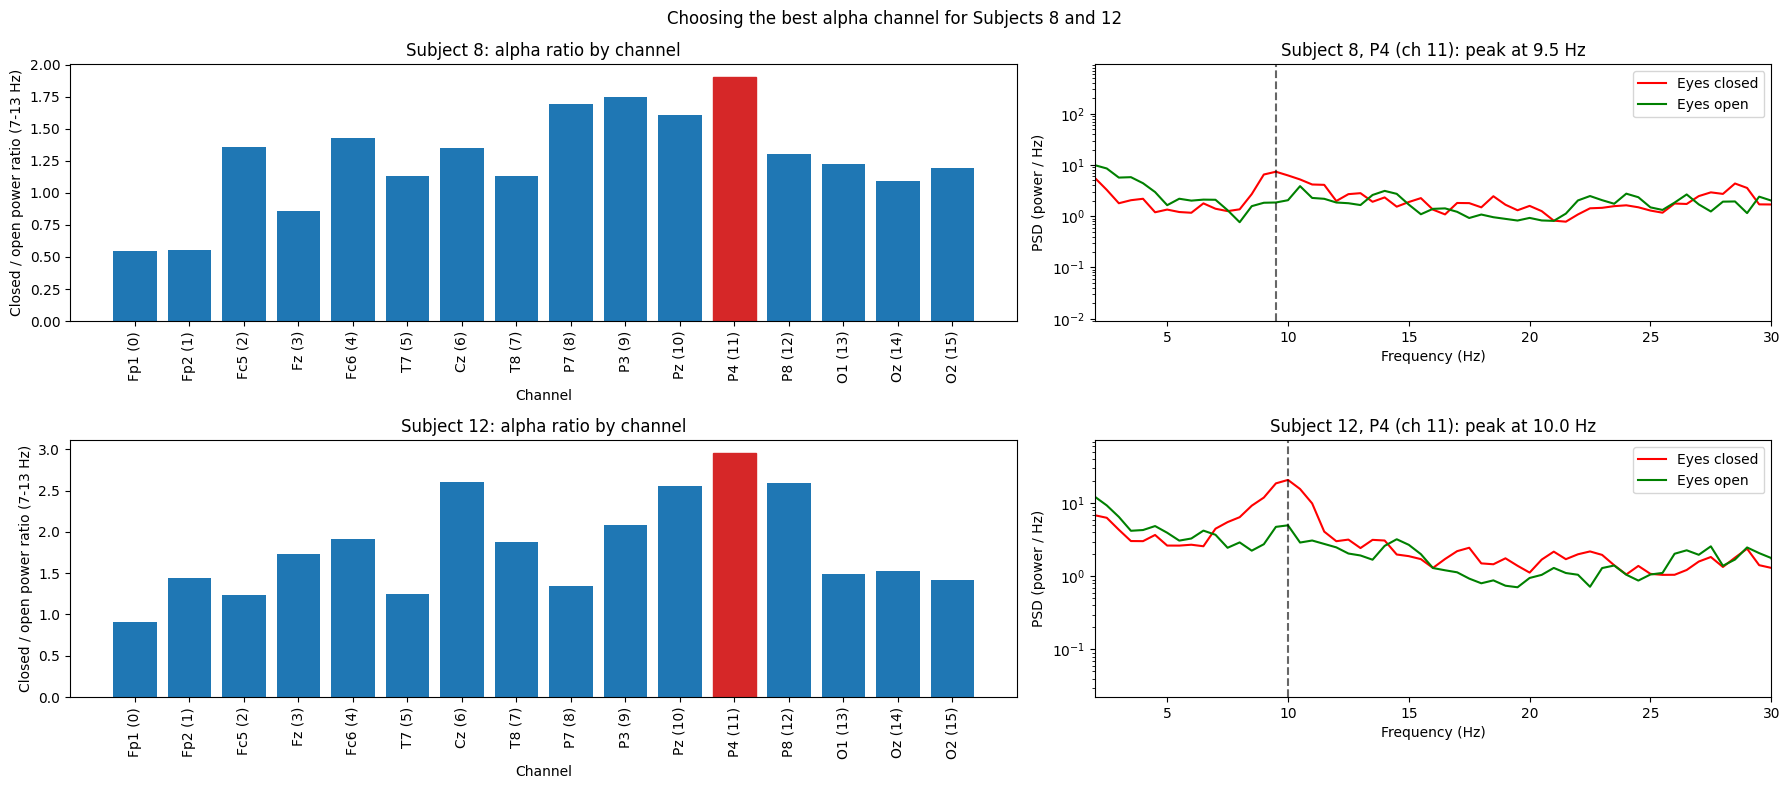

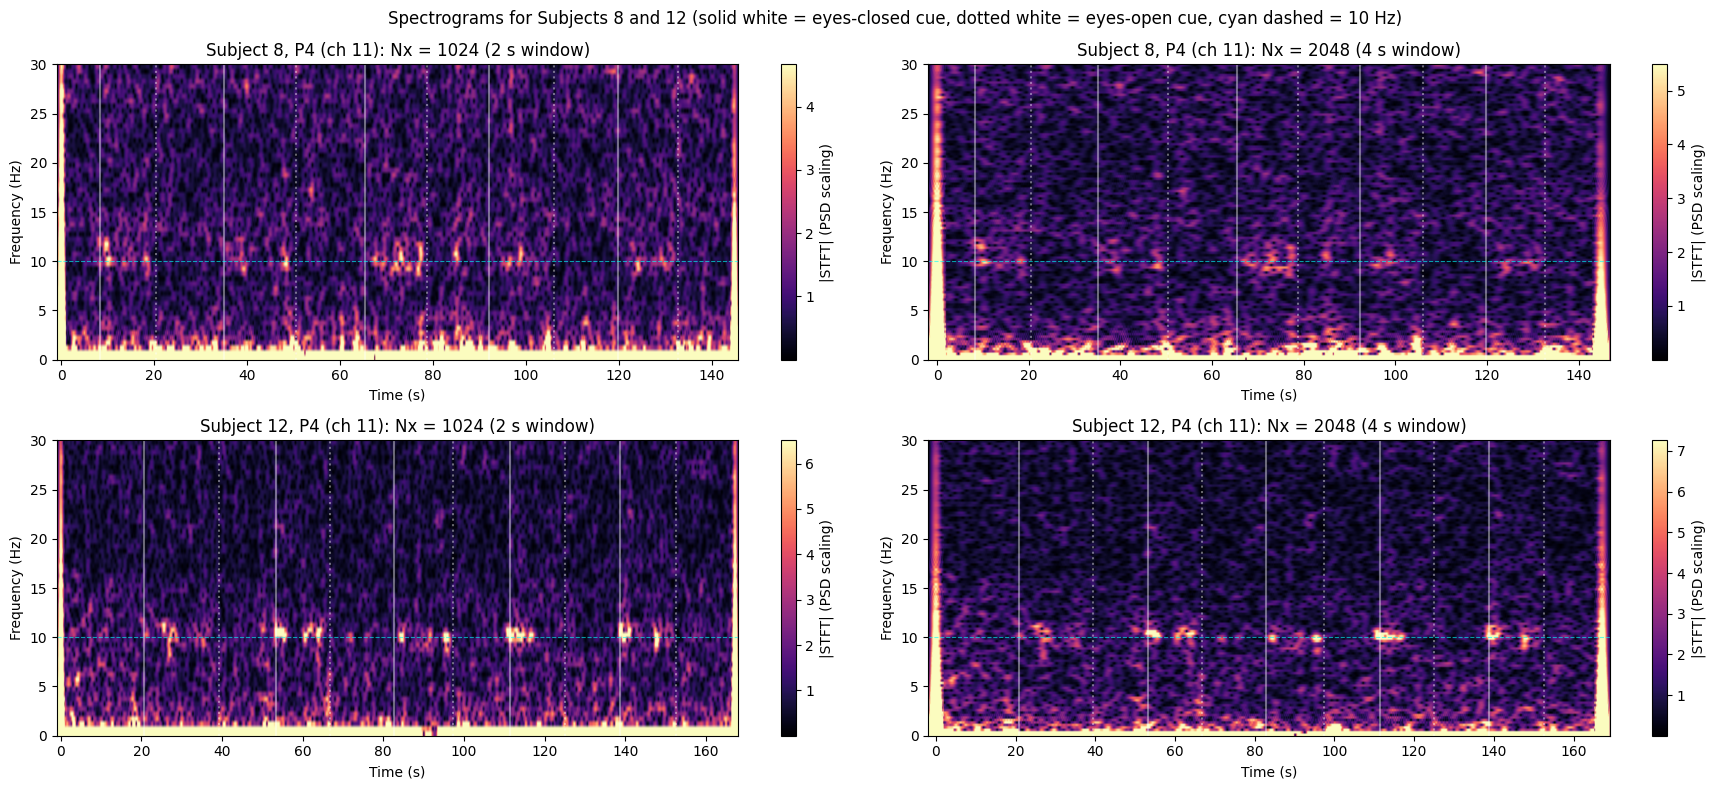

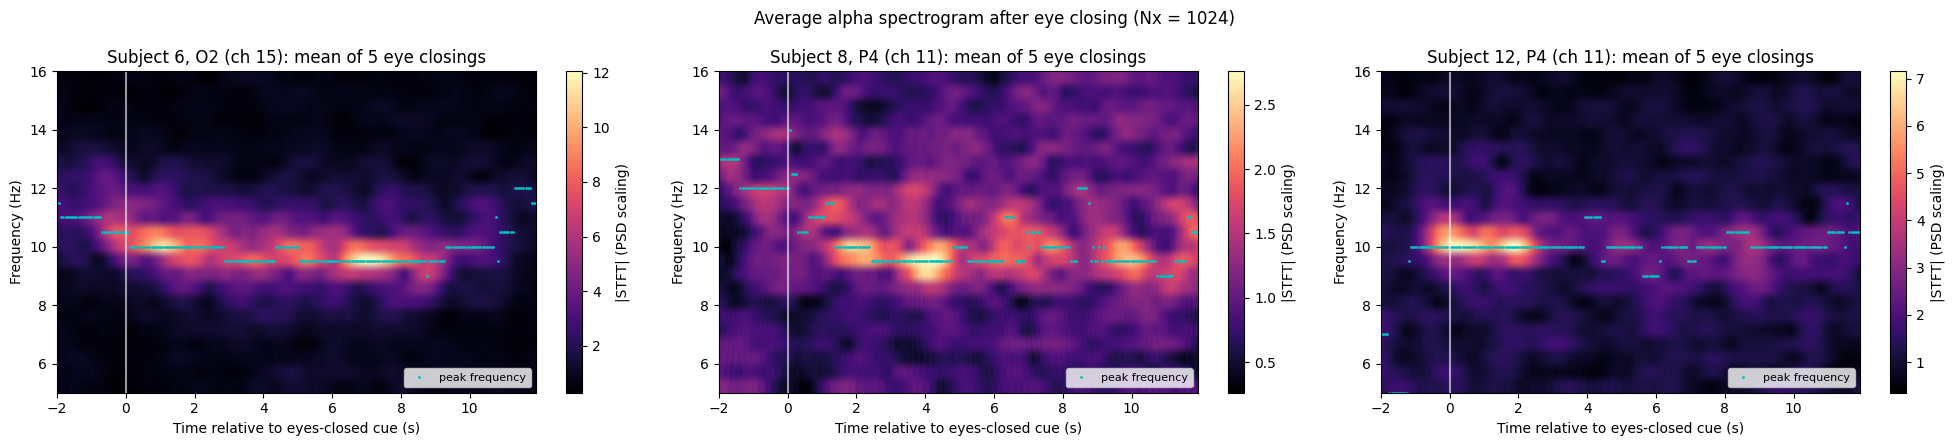

In [20]:
# ANSWER 2B
# your code here
eeg_8,  fs_8,  closed_8,  opened_8,  labels_8  = load_subject(8)
eeg_12, fs_12, closed_12, opened_12, labels_12 = load_subject(12)

subjects = {8:  (eeg_8,  fs_8,  closed_8,  opened_8,  labels_8),
            12: (eeg_12, fs_12, closed_12, opened_12, labels_12)}

def alpha_by_channel(eeg, fs_s, closed_idx, opened_idx, nperseg=1024, band=(7, 13)):
    """Mean eyes-closed PSD, eyes-open PSD, and the closed/open alpha-band ratio for every channel."""
    win = np.arange(4*fs_s) + 4*fs_s                       # same 4-8 s windows as Problem 1
    closed = np.array([eeg[i + win, :] for i in closed_idx])
    opened = np.array([eeg[i + win, :] for i in opened_idx])
    f, Pc = signal.welch(closed, fs_s, axis=1, nperseg=nperseg)
    f, Po = signal.welch(opened, fs_s, axis=1, nperseg=nperseg)
    Pc, Po = Pc.mean(axis=0), Po.mean(axis=0)              # (freqs, channels)
    sel = (f >= band[0]) & (f <= band[1])
    ratio = Pc[sel].mean(axis=0) / Po[sel].mean(axis=0)    # alpha-band power ratio per channel
    return f, Pc, Po, ratio

# --- Step 1: choose the best channel for each subject (largest closed/open alpha ratio) ---
best = {}
fig, ax = plt.subplots(2, 2, figsize=(18, 8), gridspec_kw={'width_ratios': [1.4, 1]})
for row, (subj, (eeg, fs_s, c_idx, o_idx, labs)) in enumerate(subjects.items()):
    f, Pc, Po, ratio = alpha_by_channel(eeg, fs_s, c_idx, o_idx)
    ch = int(np.argmax(ratio))
    best[subj] = ch
    sel = (f >= 7) & (f <= 13)
    peak_f = f[sel][Pc[sel, ch].argmax()]

    plot_labels = ['{} ({})'.format(lab, i) for i, lab in enumerate(labs)]
    bars = ax[row, 0].bar(plot_labels, ratio)
    bars[ch].set_color('tab:red')
    ax[row, 0].tick_params(axis='x', labelrotation=90)
    ax[row, 0].set_xlabel('Channel')
    ax[row, 0].set_ylabel('Closed / open power ratio (7-13 Hz)')
    ax[row, 0].set_title('Subject {}: alpha ratio by channel'.format(subj))

    ax[row, 1].semilogy(f, Pc[:, ch], 'r', label='Eyes closed')
    ax[row, 1].semilogy(f, Po[:, ch], 'g', label='Eyes open')
    ax[row, 1].axvline(peak_f, color='k', linestyle='--', alpha=0.6)
    ax[row, 1].set_xlim(2, 30)
    ax[row, 1].set_xlabel('Frequency (Hz)')
    ax[row, 1].set_ylabel('PSD (power / Hz)')
    ax[row, 1].set_title('Subject {}, {} (ch {}): peak at {:.1f} Hz'.format(subj, labs[ch], ch, peak_f))
    ax[row, 1].legend()

    top3 = np.argsort(ratio)[::-1][:3]
    print('Subject {}: top channels by ratio: '.format(subj) +
          ', '.join('{} (ch {}) = {:.2f}'.format(labs[i], i, ratio[i]) for i in top3) +
          ' | eyes-closed peak on best channel: {:.1f} Hz'.format(peak_f))
fig.suptitle('Choosing the best alpha channel for Subjects 8 and 12')
fig.tight_layout()

# --- Step 2: full-session spectrograms of the best channel ---
Nx_list = [1024, 2048]
fig, ax = plt.subplots(2, len(Nx_list), figsize=(18, 8))
for row, (subj, (eeg, fs_s, c_idx, o_idx, labs)) in enumerate(subjects.items()):
    ch = best[subj]
    for col, Nx in enumerate(Nx_list):
        title = 'Subject {}, {} (ch {}): Nx = {} ({:.0f} s window)'.format(subj, labs[ch], ch, Nx, Nx/fs_s)
        im = plot_spectrogram(ax[row, col], eeg[:, ch], fs_s, c_idx, o_idx, title, Nx=Nx)
        ax[row, col].axhline(10, color='cyan', linestyle='--', lw=0.8, alpha=0.6)
        fig.colorbar(im, ax=ax[row, col], label='|STFT| (PSD scaling)')
fig.suptitle('Spectrograms for Subjects 8 and 12 (solid white = eyes-closed cue, '
             'dotted white = eyes-open cue, cyan dashed = 10 Hz)')
fig.tight_layout()

# --- Step 3: average spectrogram around eye closing, all three subjects ---
# Average the spectrogram from 2 s before to 12 s after each eyes-closed cue,
# then track the peak frequency at each time point to see whether it drifts down.
Nx_zoom, hop_zoom = 1024, 32
fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
all_subj = {6: (eeg_data, fs, eyes_closed_indices, eyes_opened_indices, channel_labels, 15)}
all_subj.update({s: subjects[s] + (best[s],) for s in subjects})
for a, (subj, (eeg, fs_s, c_idx, o_idx, labs, ch)) in zip(ax, all_subj.items()):
    x = eeg[:, ch] - np.mean(eeg[:, ch])
    SFT = signal.ShortTimeFFT(signal.get_window('hamming', Nx=Nx_zoom), hop=hop_zoom, fs=fs_s, scale_to='psd')
    S = np.abs(SFT.stft(x))
    t_s = SFT.t(len(x))
    pre, post = 2, 12
    epochs = []
    for c in c_idx:
        t0 = c / fs_s
        k = np.where((t_s >= t0 - pre) & (t_s < t0 + post))[0]
        epochs.append(S[:, k[:int((pre + post) * fs_s / hop_zoom)]])
    S_avg = np.mean(epochs, axis=0)
    t_rel = np.arange(S_avg.shape[1]) * hop_zoom / fs_s - pre
    fsel = (SFT.f >= 5) & (SFT.f <= 16)
    im = a.imshow(S_avg[fsel], origin='lower', aspect='auto', cmap='magma',
                  extent=[t_rel[0], t_rel[-1], SFT.f[fsel][0], SFT.f[fsel][-1]])
    peak_track = SFT.f[fsel][S_avg[fsel].argmax(axis=0)]   # peak frequency at each time point
    a.plot(t_rel, peak_track, 'c.', ms=2, label='peak frequency')
    a.axvline(0, color='white', alpha=0.6)
    a.set_xlabel('Time relative to eyes-closed cue (s)')
    a.set_ylabel('Frequency (Hz)')
    a.set_title('Subject {}, {} (ch {}): mean of 5 eye closings'.format(subj, labs[ch], ch))
    a.legend(loc='lower right', fontsize=8)
    fig.colorbar(im, ax=a, label='|STFT| (PSD scaling)')
fig.suptitle('Average alpha spectrogram after eye closing (Nx = {})'.format(Nx_zoom))
fig.tight_layout()



**ANSWER 2B: written answer**

- Which channel(s) did you use for each subject, and why?
- Do you see a downward sweep after eye closing in Subject 8? In Subject 12? How confident are you?

_Your answer:_

I used P4 (channel 11) for both Subject 8 and Subject 12. I used the ratio because alpha is weak in these subjects, and the ratio picks out the activity that actually changes with eye state. The right panels confirm that P4 has an eyes-closed peak near 9.5 Hz (Subject 8) and 10 Hz (Subject 12).

Based on the third figure, in Subject 8 (middle panel), the peak starts near 12 Hz around the cue and settles at about 9.5–10 Hz within a few seconds, which suggests a downward sweep similar to Subject 6. In Subject 12 (right panel), the alpha stays at about 10 Hz and I see no sweep. My confidence is low for both. The full-session spectrograms in the second figure show that alpha in these subjects appears only as weak, scattered bursts, and in Subject 12 it lasts only a second or two after each closing, too short for a sweep to show.

# Problem 3: Linear filters

When we look at our power spectra, it's obvious that there is lots of energy at frequencies other than the alpha band. Let's design a linear filter to isolate the alpha signal in our EEG data. The `firls()` function designs a filter using "least squares". The parameters describe what we want from it in terms of frequency: `bands=[0, 5, 7, 12, 14, 256]` with `desired=[0, 0, 1, 1, 0, 0]` says that we want no signal at frequencies below 5 Hz, full signal between 7 and 12 Hz, and no signal above 14 Hz. The `numtaps` parameter is how long the filter is. For this kind of filter the number should be odd. We initially choose 33, which is about 0.06 s (roughly half a cycle of an 8 Hz signal at fs = 512 Hz), but you will explore the effects of longer filters.

In [21]:
b = signal.firls(numtaps=33, bands=[0, 5, 7, 12, 14, 256], desired=[0, 0, 1, 1, 0, 0], fs=fs)

We can visualize how well a filter will work using the `freqz()` function.

Text(0, 0.5, 'Response of filter (dB)')

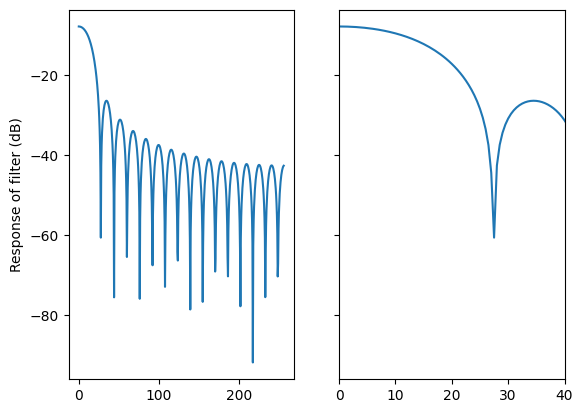

In [22]:
f, response = signal.freqz(b, fs=fs) # Filter response is a complex number. We can ignore the phase for now.

fig, ax = plt.subplots(1,2, sharey=True)
ax[0].plot(f, 20*np.log10(np.abs(response))) # 20*log10() gives the response in "dB"
ax[1].plot(f, 20*np.log10(np.abs(response)))
ax[1].set_xlim(0,40)
ax[0].set_ylabel('Response of filter (dB)')

The filter we've designed blocks frequencies pretty well above ~20 Hz, but it doesn't seem to be doing a great job at lower frequencies. Let's make it a bit longer &mdash; `numtaps=65` instead of 33.

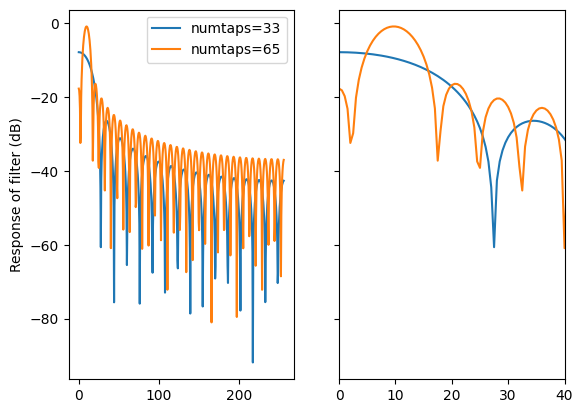

In [23]:
b2 = signal.firls(numtaps=65, bands=[0, 5, 7, 12, 14, 256], desired=[0, 0, 1, 1, 0, 0], fs=fs)
f, response2 = signal.freqz(b2, fs=fs)

fig, ax = plt.subplots(1,2, sharey=True)
ax[0].plot(f, 20*np.log10(np.abs(response)), label='numtaps=33')
ax[0].plot(f, 20*np.log10(np.abs(response2)), label='numtaps=65')
ax[1].plot(f, 20*np.log10(np.abs(response)))
ax[1].plot(f, 20*np.log10(np.abs(response2)))
ax[1].set_xlim(0,40)
ax[0].set_ylabel('Response of filter (dB)')
ax[0].legend()

Our new filter is attenuating both high and low frequencies. Now let's apply it to our EEG data. In general, when you are filtering, you should use the function `filtfilt()`. This slides the filter along the signal forward in time _and_ backward in time. The result is that signals will be smeared in time symmetrically forward and backward, as we are going to explore.

In [24]:
alpha_data = signal.filtfilt(b2, 1, eeg_data, axis=0)

Now let's look at the result in the time domain. We'll plot the same segment of signal on channels 0 and 13 as we did above, but this time also the alpha-band signal.

Text(0, 0.5, 'Channel 13 Signal')

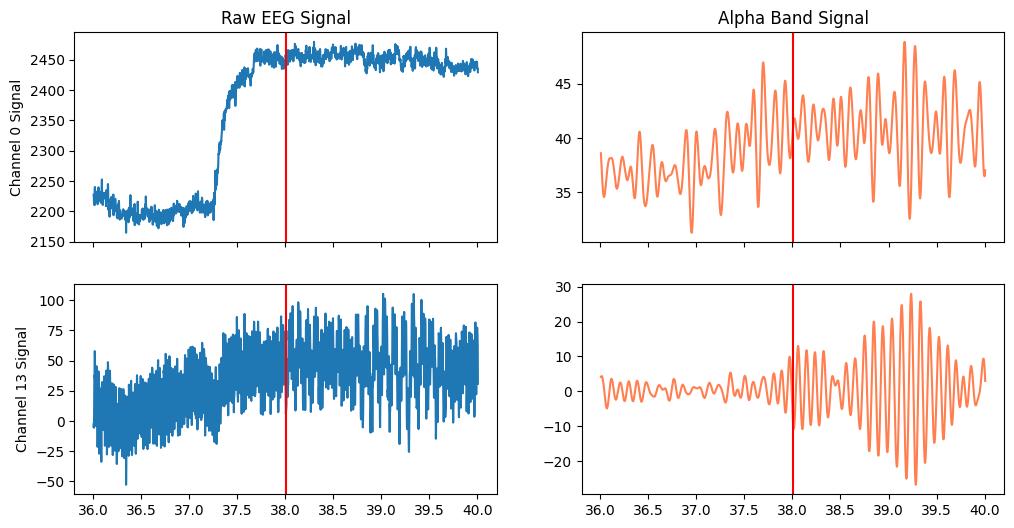

In [25]:
closed_index = eyes_closed_indices[1] # Index of second eyes closing

fig, ax = plt.subplots(2,2, figsize=(12,6), sharex=True)

ax[0,0].plot(t[closed_index - 1024: closed_index + 1024], eeg_data[closed_index - 1024: closed_index + 1024, 0])
ax[1,0].plot(t[closed_index - 1024: closed_index + 1024], eeg_data[closed_index - 1024: closed_index + 1024, 13])

ax[0,1].plot(t[closed_index - 1024: closed_index + 1024], alpha_data[closed_index - 1024: closed_index + 1024, 0], color='coral')
ax[1,1].plot(t[closed_index - 1024: closed_index + 1024], alpha_data[closed_index - 1024: closed_index + 1024, 13], color='coral')

[a.axvline(t[closed_index], color='r') for a in ax.flatten()]

ax[0,0].set_title('Raw EEG Signal')
ax[0,1].set_title('Alpha Band Signal')
ax[0,0].set_ylabel('Channel 0 Signal')
ax[1,0].set_ylabel('Channel 13 Signal')

What about the spectrograms? Let's see how filtering changes them.

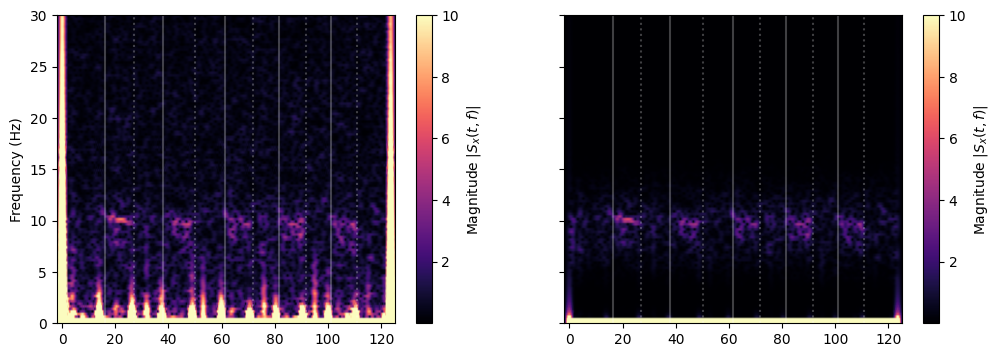

In [26]:
hamm_win = signal.get_window('hamming', Nx=2048)
SFT = signal.ShortTimeFFT(hamm_win, hop=32, fs=fs, scale_to='psd')
stft = SFT.stft(eeg_data, axis=0)

fig, axs = plt.subplots(1,2,figsize=(12,4), sharey=True, sharex=True)
im = axs[0].imshow((abs(stft[:,0,:])), origin='lower', aspect='auto',
                 extent=SFT.extent(eeg_data.shape[0]), cmap='magma', vmax=10)
fig.colorbar(im, label="Magnitude $|S_x(t, f)|$")
axs[0].set_ylabel('Frequency (Hz)')
axs[0].set_ylim(0, 30)

stft2 = SFT.stft(alpha_data, axis=0)
im2 = axs[1].imshow((abs(stft2[:,0,:])), origin='lower', aspect='auto',
                 extent=SFT.extent(eeg_data.shape[0]), cmap='magma', vmax=10)
fig.colorbar(im2, label="Magnitude $|S_x(t, f)|$")

for ax in axs:
    [ax.axvline(t_eeg[idx], color='white', alpha=0.25) for idx in eyes_closed_indices]
    [ax.axvline(t_eeg[idx], linestyle=':', color='white', alpha=0.25) for idx in eyes_opened_indices]

It looks like most of the non-alpha signal is gone, but at the lowest frequencies there is still power. Looking back at the time-domain signal, we see that around time 38.0 s, channel 0 is quite far from 0 (unlike channel 13). Frequency 0 in a power spectrum/spectrogram is equal to the mean of the signal, so when it's nonzero, the mean is still far from zero.

### What about temporal smearing?

Let's construct a fake signal and filter it to highlight temporal smearing: a 1 s long pulse of 10 Hz "alpha" in the middle of 5 s of absolute silence.

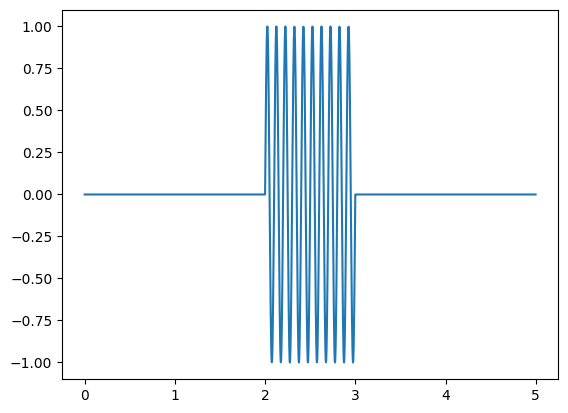

In [27]:
fake_t = np.arange(5*fs)/fs
fake_alpha = np.zeros(fake_t.shape[0])
fake_alpha[2*fs:3*fs] = np.sin(2*np.pi*10*fake_t[2*fs:3*fs])
plt.plot(fake_t, fake_alpha)

## Problem 3A (20 pts): Filter smearing

Filter the fake alpha signal with the two filters we created above (`b` and `b2`) using `filtfilt()`, and plot the results along with the original.

numtaps=33: steady amplitude = 0.11; extends 0.023 s before (0.23 cycles) and 0.023 s after (0.23 cycles); longest possible spread = (numtaps-1)/fs = 0.062 s (0.62 cycles)
numtaps=65: steady amplitude = 0.80; extends 0.105 s before (1.05 cycles) and 0.105 s after (1.05 cycles); longest possible spread = (numtaps-1)/fs = 0.125 s (1.25 cycles)


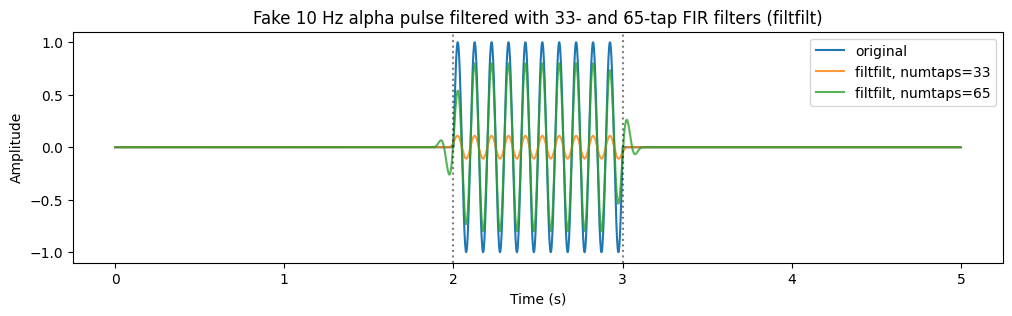

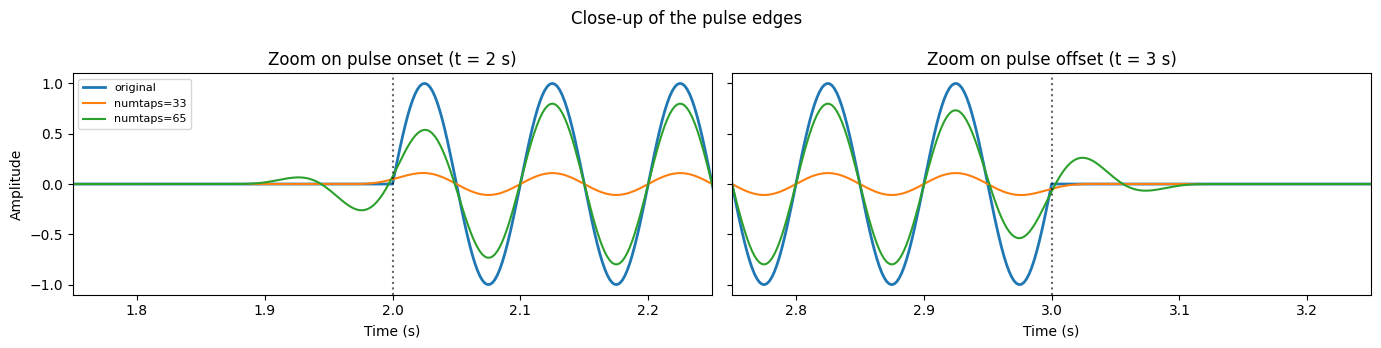

In [28]:
# ANSWER 3A
fig, ax = plt.subplots(1,1, figsize=(12,3))
ax.plot(fake_t, fake_alpha, label='original')

# your code here: filter fake_alpha with b and b2 and plot both
# Filter the fake pulse with both filters (forward + backward)
filt_33 = signal.filtfilt(b, 1, fake_alpha)
filt_65 = signal.filtfilt(b2, 1, fake_alpha)
ax.plot(fake_t, filt_33, label='filtfilt, numtaps=33', alpha=0.8)
ax.plot(fake_t, filt_65, label='filtfilt, numtaps=65', alpha=0.8)
ax.axvline(2, color='k', linestyle=':', alpha=0.5)   # true pulse start
ax.axvline(3, color='k', linestyle=':', alpha=0.5)   # true pulse end
ax.set_xlabel('Time (s)')
ax.set_ylabel('Amplitude')
ax.set_title('Fake 10 Hz alpha pulse filtered with 33- and 65-tap FIR filters (filtfilt)')
ax.legend()

# Zoom in on the start and end of the pulse
fig2, ax2 = plt.subplots(1, 2, figsize=(14, 3.5), sharey=True)
for a, edge in zip(ax2, [2, 3]):
    a.plot(fake_t, fake_alpha, label='original', lw=2)
    a.plot(fake_t, filt_33, label='numtaps=33')
    a.plot(fake_t, filt_65, label='numtaps=65')
    a.axvline(edge, color='k', linestyle=':', alpha=0.6)
    a.set_xlim(edge - 0.25, edge + 0.25)
    a.set_xlabel('Time (s)')
    a.set_title('Zoom on pulse {} (t = {} s)'.format('onset' if edge == 2 else 'offset', edge))
ax2[0].set_ylabel('Amplitude')
ax2[0].legend(fontsize=8)
fig2.suptitle('Close-up of the pulse edges')
fig2.tight_layout()

# Quantify the smearing and the amplitude
def smear_extent(y, rel_thresh=0.01):
    """How far |y| stays above 1% of its own steady-state amplitude before 2 s and after 3 s."""
    amp = np.abs(y[(fake_t > 2.3) & (fake_t < 2.7)]).max()   # steady-state amplitude in the middle of the pulse
    above = np.abs(y) > rel_thresh * amp
    lead = 2 - fake_t[(fake_t < 2) & above].min()
    lag = fake_t[(fake_t > 3) & above].max() - 3
    return lead, lag, amp

for name, y, n in [('numtaps=33', filt_33, 33), ('numtaps=65', filt_65, 65)]:
    lead, lag, amp = smear_extent(y)
    print('{}: steady amplitude = {:.2f}; extends {:.3f} s before ({:.2f} cycles) and {:.3f} s after '
          '({:.2f} cycles); longest possible spread = (numtaps-1)/fs = {:.3f} s ({:.2f} cycles)'.format(
          name, amp, lead, lead*10, lag, lag*10, (n-1)/fs, (n-1)/fs*10))
ax.legend()

**ANSWER 3A: written answer**

- How far does each filtered signal extend beyond the original pulse, in cycles of the 10 Hz signal?
- Do you notice any distortion in the shape of the output signal? Where?

_Your answer:_

The 33-tap output extends about 0.2 cycles (0.02 s) beyond the pulse on each side, and the 65-tap output extends about 1 cycle (0.1 s) on each side. I measured this as how far each output stays above 1% of its own amplitude before 2 s and after 3 s (printed values), and the zoomed-in panels of the bottom figure show the same spread.

Yes. The 65-tap output is distorted mainly at the start and end of the pulse, and the 33-tap output is distorted in amplitude across the whole pulse.

## Problem 3B (15 pts): Filter design and smearing

Now design a new filter with `numtaps=513` (same `bands` and `desired`), and look at both its frequency response and what it does to the fake alpha pulse.

numtaps=65: steady amplitude = 0.80; extends 0.105 s before (1.1 cycles) and 0.105 s after (1.1 cycles); longest possible spread = 0.125 s (1.2 cycles)
numtaps=513: steady amplitude = 1.00; extends 0.463 s before (4.6 cycles) and 0.463 s after (4.6 cycles); longest possible spread = 1.000 s (10.0 cycles)
numtaps= 33: gain at 2 Hz =   -8.0 dB, 10 Hz =  -9.6 dB, 20 Hz =  -17.3 dB, 50 Hz =  -31.5 dB
numtaps= 65: gain at 2 Hz =  -32.5 dB, 10 Hz =  -1.0 dB, 20 Hz =  -16.8 dB, 50 Hz =  -28.3 dB
numtaps=513: gain at 2 Hz =  -43.4 dB, 10 Hz =   0.0 dB, 20 Hz =  -53.9 dB, 50 Hz =  -75.3 dB


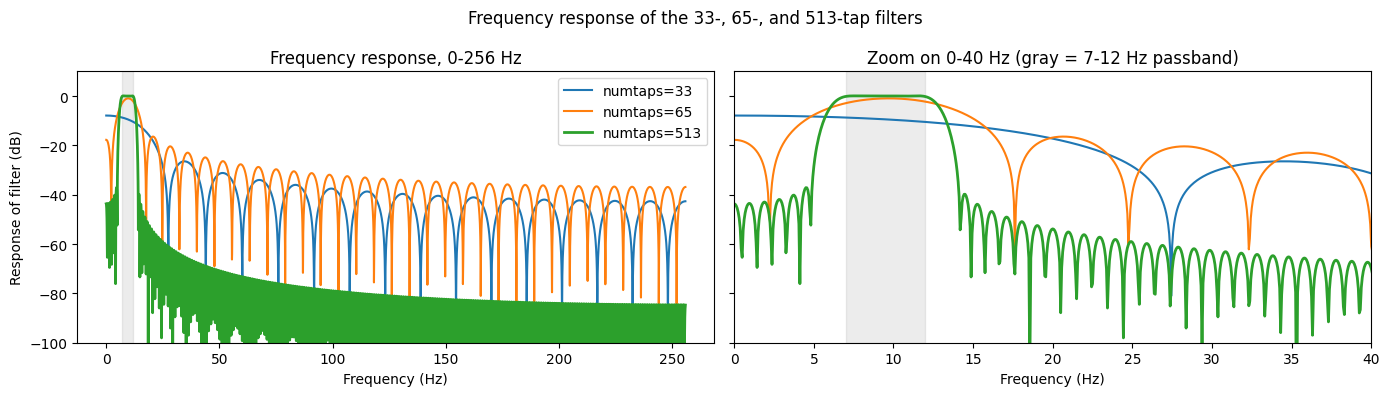

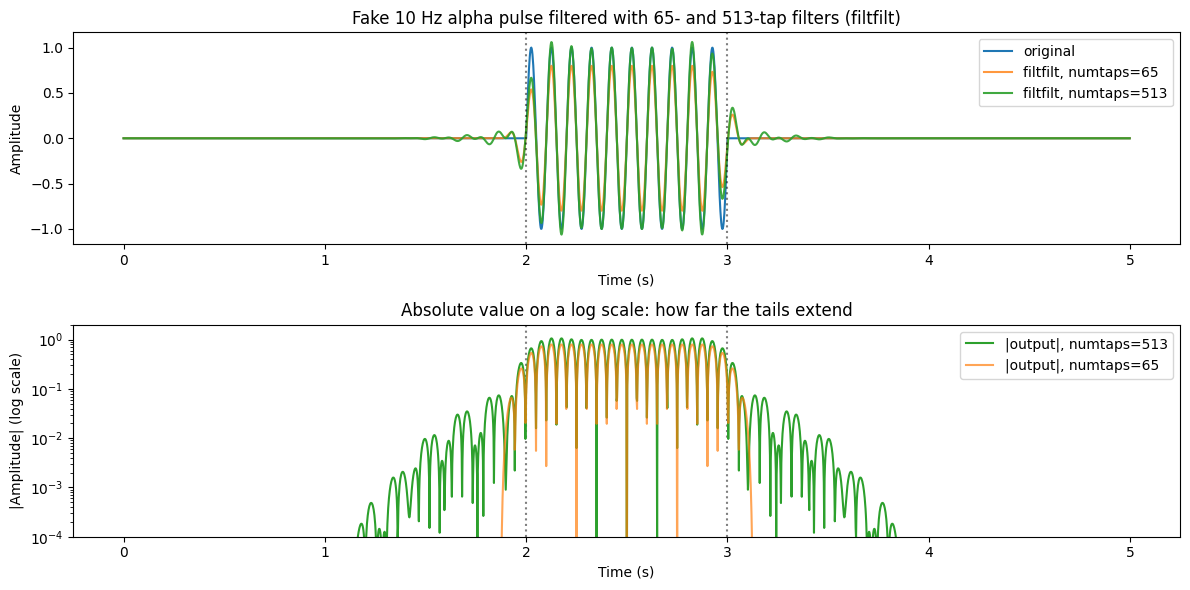

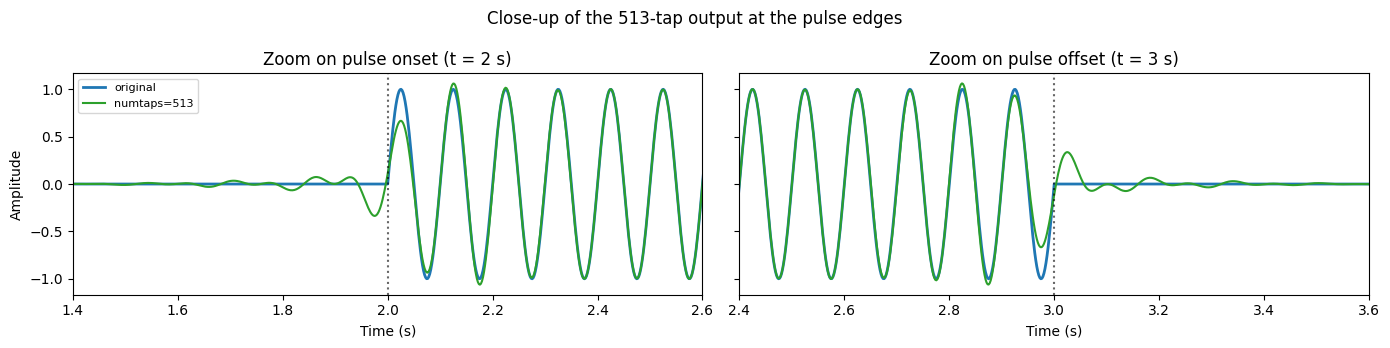

In [29]:
# ANSWER 3B
# your code here
b3 = signal.firls(numtaps=513, bands=[0, 5, 7, 12, 14, 256], desired=[0, 0, 1, 1, 0, 0], fs=fs)

# --- Figure 1: frequency response of all three filters ---
f, response3 = signal.freqz(b3, fs=fs, worN=4096)
f_33, resp_33 = signal.freqz(b, fs=fs, worN=4096)
f_65, resp_65 = signal.freqz(b2, fs=fs, worN=4096)

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for a in ax:
    a.plot(f_33, 20*np.log10(np.abs(resp_33)), label='numtaps=33')
    a.plot(f_65, 20*np.log10(np.abs(resp_65)), label='numtaps=65')
    a.plot(f, 20*np.log10(np.abs(response3)), label='numtaps=513', lw=2)
    a.axvspan(7, 12, color='gray', alpha=0.15)   # desired passband
    a.set_xlabel('Frequency (Hz)')
ax[0].set_ylabel('Response of filter (dB)')
ax[0].set_title('Frequency response, 0-256 Hz')
ax[1].set_xlim(0, 40)
ax[1].set_title('Zoom on 0-40 Hz (gray = 7-12 Hz passband)')
ax[0].set_ylim(-100, 10)
ax[0].legend()
fig.suptitle('Frequency response of the 33-, 65-, and 513-tap filters')
fig.tight_layout()

# --- Figure 2: what the 513-tap filter does to the fake alpha pulse ---
filt_513 = signal.filtfilt(b3, 1, fake_alpha)

fig2, ax2 = plt.subplots(2, 1, figsize=(12, 6))
ax2[0].plot(fake_t, fake_alpha, label='original')
ax2[0].plot(fake_t, filt_65, label='filtfilt, numtaps=65', alpha=0.8)
ax2[0].plot(fake_t, filt_513, label='filtfilt, numtaps=513', alpha=0.9)
for a in ax2:
    a.axvline(2, color='k', linestyle=':', alpha=0.5)
    a.axvline(3, color='k', linestyle=':', alpha=0.5)
    a.set_xlabel('Time (s)')
    a.set_ylabel('Amplitude')
ax2[0].set_title('Fake 10 Hz alpha pulse filtered with 65- and 513-tap filters (filtfilt)')
ax2[0].legend(loc='upper right')

# Same outputs on a log scale, so the small smeared tails are visible
ax2[1].semilogy(fake_t, np.abs(filt_513) + 1e-6, color='tab:green', label='|output|, numtaps=513')
ax2[1].semilogy(fake_t, np.abs(filt_65) + 1e-6, color='tab:orange', alpha=0.7, label='|output|, numtaps=65')
ax2[1].set_ylim(1e-4, 2)
ax2[1].set_ylabel('|Amplitude| (log scale)')
ax2[1].set_title('Absolute value on a log scale: how far the tails extend')
ax2[1].legend(loc='upper right')
fig2.tight_layout()

# --- Figure 3: zoom on the pulse edges ---
fig3, ax3 = plt.subplots(1, 2, figsize=(14, 3.5), sharey=True)
for a, edge in zip(ax3, [2, 3]):
    a.plot(fake_t, fake_alpha, label='original', lw=2)
    a.plot(fake_t, filt_513, label='numtaps=513', color='tab:green')
    a.axvline(edge, color='k', linestyle=':', alpha=0.6)
    a.set_xlim(edge - 0.6, edge + 0.6)
    a.set_xlabel('Time (s)')
    a.set_title('Zoom on pulse {} (t = {} s)'.format('onset' if edge == 2 else 'offset', edge))
ax3[0].set_ylabel('Amplitude')
ax3[0].legend(fontsize=8)
fig3.suptitle('Close-up of the 513-tap output at the pulse edges')
fig3.tight_layout()

# --- Numbers: smearing and gain at key frequencies ---
def smear_extent(y, rel_thresh=0.01):
    """How far |y| stays above 1% of its own steady-state amplitude before 2 s and after 3 s."""
    amp = np.abs(y[(fake_t > 2.3) & (fake_t < 2.7)]).max()
    above = np.abs(y) > rel_thresh * amp
    lead = 2 - fake_t[(fake_t < 2) & above].min()
    lag = fake_t[(fake_t > 3) & above].max() - 3
    return lead, lag, amp

for name, y, n in [('numtaps=65', filt_65, 65), ('numtaps=513', filt_513, 513)]:
    lead, lag, amp = smear_extent(y)
    print('{}: steady amplitude = {:.2f}; extends {:.3f} s before ({:.1f} cycles) and {:.3f} s after '
          '({:.1f} cycles); longest possible spread = {:.3f} s ({:.1f} cycles)'.format(
          name, amp, lead, lead*10, lag, lag*10, (n-1)/fs, (n-1)/fs*10))

for name, ff, rr in [('33', f_33, resp_33), ('65', f_65, resp_65), ('513', f, response3)]:
    g = lambda hz: 20*np.log10(np.abs(rr[np.abs(ff - hz).argmin()]))
    print('numtaps={:>3}: gain at 2 Hz = {:6.1f} dB, 10 Hz = {:5.1f} dB, 20 Hz = {:6.1f} dB, 50 Hz = {:6.1f} dB'.format(
          name, g(2), g(10), g(20), g(50)))

**ANSWER 3B: written answer**

- How far does the 513-tap output extend beyond the pulse? Where do you notice the most signal distortion?
- What do you gain and what do you lose by using the longer filter?

_Your answer:_

The 513-tap output extends about 4.6 cycles (0.46 s) beyond the pulse on each side (printed values), with tiny tails reaching about 1.2 s and 3.8 s in the log-scale panel of the second figure. The most distortion is at the start and end of the pulse. The close-up figure shows ringing that begins about 0.4 s before the pulse, a weak first cycle followed by an overshoot, and mirror-image ringing after 3 s.

We gain frequency selectivity and lose time precision. The frequency-response figure shows that the 513-tap filter has a flat passband (0 dB at 10 Hz), steep edges, and strong rejection outside the band (−54 dB at 20 Hz and −75 dB at 50 Hz, versus −17 dB and −28 dB for 65 taps). The cost is that every change in the signal is spread over almost half a second on each side, so short alpha bursts would look longer and less sharply timed than they really are.

# Problem 4 (30 pts; required for ELEC 587, extra credit for ELEC 380): Quantifying the alpha sweep

Using the Fp channels, re-align the eye-closing epochs to start when the eye-muscle artifact actually indicates the eyes closed. Extract each eye-closing event using the alpha-filtered data and calculate the average alpha spectrogram following eye closing. Extract the peak frequency at each time point. If you combine the 5 observations from Subjects 6, 8, and 12, for each time point you should have 15 samples. Fit a linear regression to these samples and report the statistical significance of its slope.

ELEC 380 students not attempting this problem: leave these cells as they are.

Subject  6: true closing relative to cue (s): [-2.48 -0.67 -1.69 -1.26 -1.29]
Subject  8: true closing relative to cue (s): [-2.38 -1.26 -2.1  -2.12 -1.18]
Subject 12: true closing relative to cue (s): [-1.79 -1.09 -1.54 -0.91 -0.95]
Peak-frequency matrix: 15 eye closings x 49 time points

Pooled regression (735 points): slope = -0.102 Hz/s, intercept = 10.50 Hz, r = -0.19, p = 1.84e-07
Per-closing slopes (Hz/s): [-0.148 -0.19  -0.073 -0.107 -0.16  -0.014 -0.2   -0.003 -0.014 -0.498
  0.027 -0.254  0.289 -0.048 -0.136]
Mean per-closing slope = -0.102 Hz/s, 13 of 15 negative, t(14) = -2.33, p = 0.0355
  Subject  6: mean slope = -0.136 Hz/s (5 of 5 negative)
  Subject  8: mean slope = -0.146 Hz/s (5 of 5 negative)
  Subject 12: mean slope = -0.024 Hz/s (3 of 5 negative)


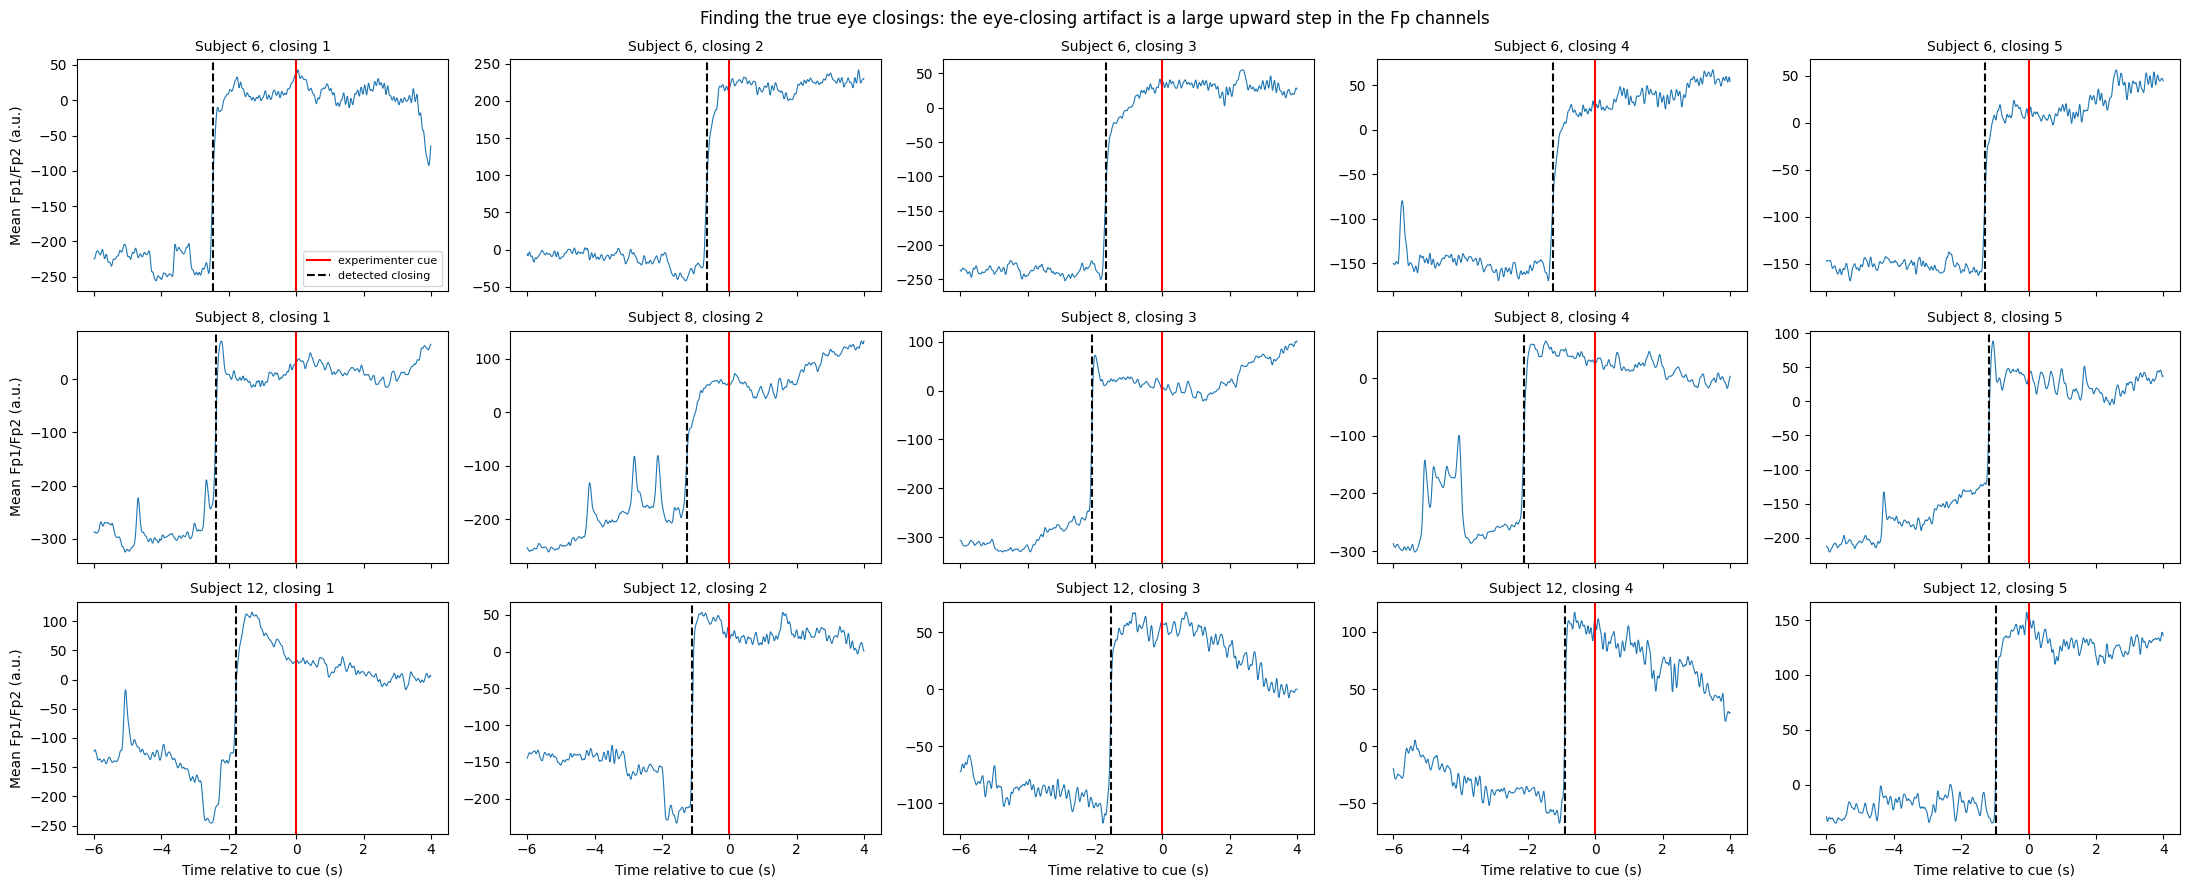

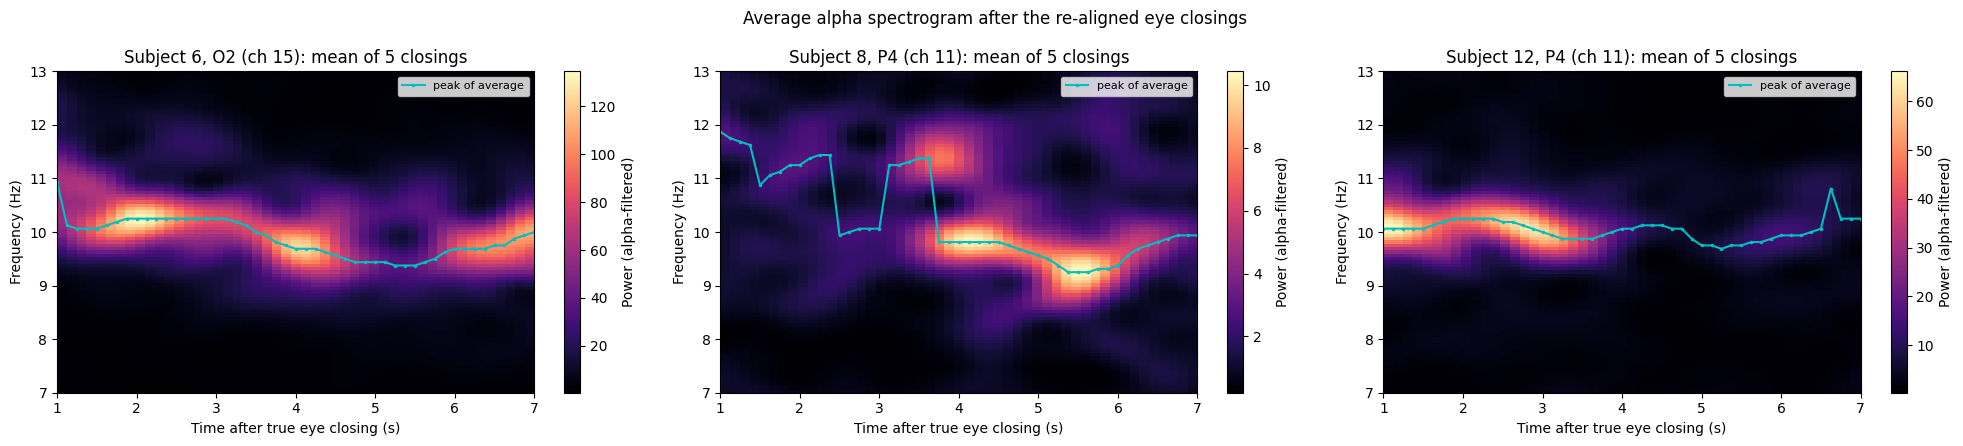

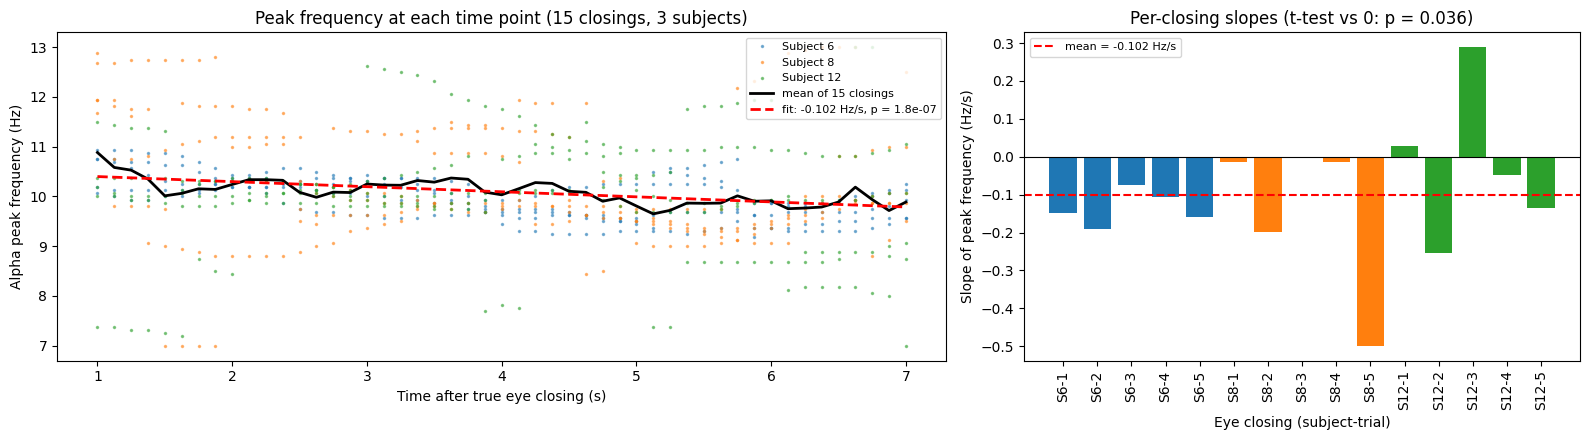

In [33]:
# ANSWER 4
# your code here

# ANSWER 4
from scipy import stats

# ---------- Settings ----------
subj_info = {6: 15, 8: 11, 12: 11}     # subject -> alpha channel chosen in Problems 1B / 2B (O2, P4, P4)
search_win = (-4.0, 1.0)               # look for the true eye closing from 4 s before to 1 s after the cue
step_half = 0.25                       # step detector compares 0.25 s after vs 0.25 s before each sample
t_start, t_end = 1.0, 7.0              # spectrogram window centers, in s after the true eye closing
Nx_a, hop_a, mfft_a = 1024, 64, 8192   # 2 s Hamming window, 0.125 s hop, zero-padded to 0.0625 Hz bins
f_lo, f_hi = 7.0, 13.0                 # range searched for the alpha peak

# Alpha filter: same design idea as Problem 3, but 513 taps and a wider flat passband (6-14 Hz),
# so the filter itself does not pull the peak toward the center of the band.
b_alpha = signal.firls(numtaps=513, bands=[0, 4, 6, 14, 16, fs/2], desired=[0, 0, 1, 1, 0, 0], fs=fs)

def find_true_closings(eeg, fs_s, cues):
    """Eye closing = the largest upward step in the mean Fp1/Fp2 signal near each cue."""
    fp = eeg[:, 0:2].mean(axis=1)
    fp = signal.filtfilt(np.ones(int(0.05*fs_s))/int(0.05*fs_s), 1, fp)   # 50 ms moving average
    h = int(step_half * fs_s)
    true_idx = []
    for c in cues:
        cand = np.arange(c + int(search_win[0]*fs_s), c + int(search_win[1]*fs_s))
        step = np.array([fp[i:i+h].mean() - fp[i-h:i].mean() for i in cand])
        true_idx.append(int(cand[np.argmax(step)]))
    return np.array(true_idx), fp

# ---------- Step 1: re-align the eye closings using the Fp channels ----------
data = {}
fig, ax = plt.subplots(3, 5, figsize=(22, 9), sharex=True)
for r, (subj, ch) in enumerate(subj_info.items()):
    eeg_s, fs_s, closed_s, opened_s, labels_s = load_subject(subj)
    true_idx, fp = find_true_closings(eeg_s, fs_s, closed_s)
    data[subj] = (eeg_s, fs_s, closed_s, opened_s, labels_s, true_idx)
    print('Subject {:2d}: true closing relative to cue (s):'.format(subj),
          np.round((true_idx - closed_s) / fs_s, 2))
    for k, (c, tc) in enumerate(zip(closed_s, true_idx)):
        seg = np.arange(c - 6*fs_s, c + 4*fs_s)
        a = ax[r, k]
        a.plot((seg - c)/fs_s, fp[seg] - np.median(fp[seg]), lw=0.8)
        a.axvline(0, color='r', label='experimenter cue')
        a.axvline((tc - c)/fs_s, color='k', linestyle='--', label='detected closing')
        a.set_title('Subject {}, closing {}'.format(subj, k+1), fontsize=10)
        if k == 0:
            a.set_ylabel('Mean Fp1/Fp2 (a.u.)')
        if r == 2:
            a.set_xlabel('Time relative to cue (s)')
ax[0, 0].legend(fontsize=8, loc='lower right')
fig.suptitle('Finding the true eye closings: the eye-closing artifact is a large upward step in the Fp channels')
fig.tight_layout()

# ---------- Step 2: alpha-filter, compute spectrograms aligned to the true closings ----------
peak_freqs = []      # one row per eye closing (15 rows), one column per time point
avg_specs = {}
for subj, ch in subj_info.items():
    eeg_s, fs_s, closed_s, opened_s, labels_s, true_idx = data[subj]
    x = signal.filtfilt(b_alpha, 1, eeg_s[:, ch] - eeg_s[:, ch].mean())
    SFT = signal.ShortTimeFFT(signal.get_window('hamming', Nx_a), hop=hop_a, fs=fs_s,
                              mfft=mfft_a, scale_to='psd')
    S = np.abs(SFT.stft(x))**2                     # power spectrogram
    t_s = SFT.t(len(x))
    fsel = (SFT.f >= f_lo) & (SFT.f <= f_hi)
    f_alpha = SFT.f[fsel]
    n_t = int(round((t_end - t_start) * fs_s / hop_a)) + 1      # same number of time points for every closing
    t_rel = t_start + np.arange(n_t) * hop_a / fs_s              # time after the true closing (s)
    epochs = []
    for tc in true_idx:
        k0 = np.searchsorted(t_s, tc/fs_s + t_start)             # first window centered >= t_start after closing
        E = S[fsel][:, k0:k0 + n_t]
        epochs.append(E)
        peak_freqs.append(f_alpha[E.argmax(axis=0)])            # peak frequency at each time point
    avg_specs[subj] = (np.mean(epochs, axis=0), f_alpha, labels_s[ch], ch)

peak_freqs = np.array(peak_freqs)                  # shape (15, n_times)
n_ep, n_t = peak_freqs.shape
print('Peak-frequency matrix: {} eye closings x {} time points'.format(n_ep, n_t))

# ---------- Step 3: linear regression of peak frequency on time ----------
t_all = np.tile(t_rel, n_ep)
f_all = peak_freqs.ravel()
reg = stats.linregress(t_all, f_all)
print('\nPooled regression ({} points): slope = {:.3f} Hz/s, intercept = {:.2f} Hz, r = {:.2f}, p = {:.2e}'.format(
      len(f_all), reg.slope, reg.intercept, reg.rvalue, reg.pvalue))

# Neighboring time points share most of their 2 s window, so they are not independent and the pooled
# p-value is too optimistic. A more conservative test: one slope per eye closing, then a one-sample t-test.
ep_slopes = np.array([stats.linregress(t_rel, pf).slope for pf in peak_freqs])
tt = stats.ttest_1samp(ep_slopes, 0)
print('Per-closing slopes (Hz/s):', np.round(ep_slopes, 3))
print('Mean per-closing slope = {:.3f} Hz/s, {} of {} negative, t({}) = {:.2f}, p = {:.4f}'.format(
      ep_slopes.mean(), int((ep_slopes < 0).sum()), n_ep, n_ep - 1, tt.statistic, tt.pvalue))
for i, subj in enumerate(subj_info):
    s_sl = ep_slopes[5*i:5*i+5]
    print('  Subject {:2d}: mean slope = {:.3f} Hz/s ({} of 5 negative)'.format(subj, s_sl.mean(), int((s_sl < 0).sum())))

# ---------- Figures ----------
fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
for a, (subj, (S_avg, f_alpha, lab, ch)) in zip(ax, avg_specs.items()):
    im = a.imshow(S_avg, origin='lower', aspect='auto', cmap='magma',
                  extent=[t_rel[0], t_rel[-1], f_alpha[0], f_alpha[-1]])
    a.plot(t_rel, f_alpha[S_avg.argmax(axis=0)], 'c.-', ms=3, label='peak of average')
    a.set_xlabel('Time after true eye closing (s)')
    a.set_ylabel('Frequency (Hz)')
    a.set_title('Subject {}, {} (ch {}): mean of 5 closings'.format(subj, lab, ch))
    a.legend(loc='upper right', fontsize=8)
    fig.colorbar(im, ax=a, label='Power (alpha-filtered)')
fig.suptitle('Average alpha spectrogram after the re-aligned eye closings')
fig.tight_layout()

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [1.6, 1]})
colors = {6: 'tab:blue', 8: 'tab:orange', 12: 'tab:green'}
for i, subj in enumerate(subj_info):
    for j in range(5):
        ax[0].plot(t_rel, peak_freqs[5*i + j], '.', color=colors[subj], ms=3, alpha=0.5,
                   label='Subject {}'.format(subj) if j == 0 else None)
ax[0].plot(t_rel, peak_freqs.mean(axis=0), 'k-', lw=2, label='mean of 15 closings')
ax[0].plot(t_rel, reg.intercept + reg.slope*t_rel, 'r--', lw=2,
           label='fit: {:.3f} Hz/s, p = {:.1e}'.format(reg.slope, reg.pvalue))
ax[0].set_xlabel('Time after true eye closing (s)')
ax[0].set_ylabel('Alpha peak frequency (Hz)')
ax[0].set_title('Peak frequency at each time point (15 closings, 3 subjects)')
ax[0].legend(fontsize=8, loc='upper right')

ax[1].bar(np.arange(n_ep), ep_slopes, color=[colors[s] for s in subj_info for _ in range(5)])
ax[1].axhline(0, color='k', lw=0.8)
ax[1].axhline(ep_slopes.mean(), color='r', linestyle='--', label='mean = {:.3f} Hz/s'.format(ep_slopes.mean()))
ax[1].set_xticks(np.arange(n_ep))
ax[1].set_xticklabels(['S{}-{}'.format(s, j+1) for s in subj_info for j in range(5)], rotation=90)
ax[1].set_xlabel('Eye closing (subject-trial)')
ax[1].set_ylabel('Slope of peak frequency (Hz/s)')
ax[1].set_title('Per-closing slopes (t-test vs 0: p = {:.3f})'.format(tt.pvalue))
ax[1].legend(fontsize=8)
fig.tight_layout()

**ANSWER 4: written answer**

- How did you find the true eye-closing times, and what window after eye closing did you analyze?
- What is the slope of the regression, and is it statistically significant? What does that tell you?

_Your answer:_

# Wavelet spectrogram (for edification, not graded)

Below is some sample code using the `ghostipy` package from Rice. You'll need to `pip install ghostipy` to use it (`!pip install ghostipy` in Colab). One thing the wavelet spectrogram makes clear (also apparent in the filtered time series) is that our alpha actually occurs in pulses, as opposed to as a continuous oscillation. This cell is skipped automatically if `ghostipy` is not installed.

In [31]:
try:
    import ghostipy as gsp
except ImportError:
    gsp = None
    print('ghostipy not installed; skipping the wavelet example.')

if gsp is not None:
    gamma = 3
    beta = 25 # decrease beta to improve temporal resolution, increase to increase frequency resolution

    cwtcoefs, _, freq, cwtts, _ = gsp.cwt(
        eeg_data[:,13], freq_limits=[1, 30], fs=fs,
        wavelet=gsp.MorseWavelet(gamma=gamma, beta=beta))

    cwt_power = cwtcoefs.imag**2 + cwtcoefs.real**2
    ff = np.flipud(freq)

    # Wavelets sample across logarithmically spaced frequencies. To display these nicely:
    @plt.FuncFormatter
    def fake_log(x, pos):
        df = (np.log(ff[-1]) - np.log(ff[0]))/(len(ff) - 1)
        f = np.exp(df*x + np.log(ff[0]))
        return '{:4.0f}'.format(f)

    fig, ax = plt.subplots(1,1, figsize=(6,4))
    im = ax.imshow(cwt_power, interpolation=None, aspect='auto',
                   extent=[t_eeg[0], t_eeg[-1],0,len(freq)-1],
                   cmap=plt.cm.magma, vmax=250)
    ax.yaxis.set_major_formatter(fake_log)
    plt.colorbar(im)
    [ax.axvline(t_eeg[idx], color='white', alpha=0.25) for idx in eyes_closed_indices]
    [ax.axvline(t_eeg[idx], linestyle=':', color='white', alpha=0.25) for idx in eyes_opened_indices];

ghostipy not installed; skipping the wavelet example.


# End of homework

After *Restart and Run All*, the cell below should print its message. If it didn't, an error stopped the notebook somewhere above; find it and fix it (or comment it out) before submitting.

In [32]:
print('Reached the end of HW7.', 'NetID:', NETID if NETID else '(NETID is empty! Set it in the setup cell.)')

Reached the end of HW7. NetID: sj127
